# Top-20 teachers × K-rungs, cross-init — the `top20-krungs` campaigns (`ds1` + `ws1`)

**The existence/peak arm of the K-rung campaign (launched 2026-07-28).** §1–8 cover the `data-seed1` arm; **§9 adds the `weight-seed1` arm** (`top20-krungs-ws1`, drained 2026-07-30) and the paired contrast between the two inits.

 The 20 most
distillable dog teachers (pythia-160m, tseed 1; ranked by std-recipe ep20 *same-model* test
p in a single-seed screen) are each cross-distilled into the **data-seed1** student base at
**25 student-HP cells** placed on rungs of the collapse-law composite

$$K = \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\; c=-0.085,$$

spanning $K/K^\ast$ 0.29–1.41 around the data-seed1 anchor $K^\ast = 7.84\times10^{-4}$
(both fitted by the `law-*` campaign, `collapse_law_generality.ipynb`). Student ep20,
**seed 1 only**.

The cells arrived in **two waves**, and the wave is carried as a *column*, not as a filter:

- **Wave 1 — 16 pre-registered cells**, two contrasting $(\alpha, r)$ realizations per rung
  plus the std anchor, placed before any data existed. Rank reaches only r16.
- **Wave 2 — 9 rank-extension cells** appended 2026-07-28, pushing rank to r32/r64. Six
  re-realize existing rungs at high rank (**fixed-$K$ twins**); three fill the high-rank
  corners.

Merged, the design spans **rank 4–64 at overlapping $K$** — which is what identifies the
rank exponent $c$ at all (§5 refit, §7). Every descriptive section below therefore uses all
25 cells; only the pre-registration claim (§5b, §5 refit) is *additionally* reported split
by wave, since wave-2 placement was informed by early law-grid reads.

Questions this notebook answers:

1. **Per-teacher student-HP response** — the 2-D (lr × r/α) heatmaps, one per teacher (§3–4).
2. **Does the law transfer?** The exponents and $K^\ast$ were fitted on 3 teacher lineages;
   here 20 held-out teachers each cross a pre-registered boundary. Verified means: collapse
   is monotone in design-$K$ per teacher, the pooled boundary sits near $K/K^\ast = 1$, and
   the thresholded law classifies cells correctly (§5–6).
3. **Is $K$ a sufficient statistic at high rank?** Fixed-$K$ twins at r32/r64 must live and
   die exactly like their low-rank rung-mates (§7).

Data: `students/dog/pythia-160m-data-seed1/from_<tag>_tseed1_nbase-pythia-160m/ex10-20_prefix_n100k/ep20_*`,
read through `subliminal_learning.analysis.collapse_law.load_law_runs`. The campaign may
still be draining when this runs — every section prints its coverage and tolerates missing
cells; re-run to refresh.

The **`weight-seed1` arm (§9)** reruns the same 20 teachers over the same wave-1+2 cells on the other student init. It is the sharper test of generality: a different init means a different fitted $K^\ast$, and because the ws1 queue reuses the ds1 cell tags verbatim, its cells land ~1.13× higher against their own anchor. Read §9 before quoting any cross-init number from §1–8 — several of them (the collapse threshold in particular) are arm-specific.

## Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import (
    add_lora_label, parse_param_tag, read_cell_manifest, read_json, read_queue_jobs,
)
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")  # statsmodels separation chatter on a near-separable design
pd.set_option("display.width", 200)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# Design constants — what the rungs were PLACED with (law-* campaign fit, ds1 anchor).
# This notebook treats them as a pre-registered prediction, not something to be tuned here.
B_LAW, C_LAW = cl.B_LAW, cl.C_LAW
KSTAR_DESIGN = cl.KSTAR_DS1_DESIGN
STUDENT_BASE = "pythia-160m-data-seed1"

# Design-time K of a student cell tag, from the pre-registered exponents.
design_K = cl.k_from_tag


def cell_rank(tag: str) -> int:
    """LoRA rank of a student cell tag."""
    return int(parse_param_tag(tag)["rank"])


# --------------------------------------------------------------------------------------
# The cell design — 25 cells that arrived in two waves. The wave is carried as a COLUMN
# (`prereg`), NOT as a filter: every descriptive section uses the union, and only the
# pre-registration claim (§5b, §5 refit) is additionally reported split by wave.
# --------------------------------------------------------------------------------------

# Wave 1 — the 16 pre-registered cells (2 contrasting (α, r) realizations per K/K* rung +
# the std anchor). Frozen from run_logs/queue/top20-krungs-ds1/jobs.jsonl so the notebook
# does not depend on the queue tree surviving.
CAMPAIGN_CELLS = [
    "ep20_lr8e-5_r4a8", "ep20_lr2e-4_r8a2", "ep20_lr3e-4_r4a2", "ep20_lr5e-5_r16a64",
    "ep20_lr4e-4_r8a2", "ep20_lr8e-5_r4a32", "ep20_lr1e-4_r8a32", "ep20_lr8e-5_r16a64",
    "ep20_lr5e-4_r4a2", "ep20_lr8e-5_r8a64", "ep20_lr4e-4_r8a4", "ep20_lr8e-5_r4a64",
    "ep20_lr1e-4_r4a64", "ep20_lr8e-4_r16a2", "ep20_lr8e-4_r4a2", "ep20_lr2e-4_r16a32",
]

# Wave 2 — the rank extension (180 jobs appended 2026-07-28). Wave 1 stops at r16, so the
# rank term rode along untested and c was barely identified. Six of these re-realize
# existing rungs at r32/r64 — the fixed-K twins, which are the identifying contrast (§7) —
# and three fill the high-rank corners. Merged with wave 1 the design spans r4–r64 at
# overlapping K, which is what actually pins c down (§5 refit).
# (A deep K/K* = 1.85 cell was cut before running — far past the cliff, foregone outcome.)
RANK_PROBE_CELLS = [
    "ep20_lr8e-5_r64a16",   # 0.34
    "ep20_lr8e-5_r32a32",   # 0.53
    "ep20_lr1e-4_r64a32",   # 0.63
    "ep20_lr8e-5_r32a64",   # 0.78  (std-anchor twin)
    "ep20_lr1e-4_r64a64",   # 0.92
    "ep20_lr1e-4_r16a64",   # 1.04
    "ep20_lr8e-4_r64a2",    # 1.06
    "ep20_lr4e-4_r64a8",    # 1.15
    "ep20_lr3e-4_r32a16",   # 1.35
]

# Wave 3 — the low-α high-rank extension (queued 2026-07-29, appended to the
# top20-krungs-ds1 queue; job list run_logs/top20krungs_alphalow_jobs.jsonl). In the ALIVE
# band every wave-2 high-rank cell carries a LARGE α (0.34→α16, 0.53→α32, 0.63→α32,
# 0.78→α64, 0.92→α64) — the only low-α high-rank cells sit past the cliff — so "high rank
# buys headroom" (§7) was confounded with high α, and b was identified almost entirely off
# low-rank cells. These add low-α realizations at r32/r64 on two populated alive rungs.
#
# Scope trimmed on 2026-07-29 (Angela): α/r >= 0.125, the lowest LoRA scale already in the
# design (r16a2, r64a8). That drops r64a2 (α/r 0.031), r64a4 and r32a2 (0.0625) — degenerate
# corners well outside the range the rest of the campaign covers — and keeps 4 cells:
#     rung 0.63:  r32a4 (α/r .125), r32a8 (.25), r64a8 (.125)      rung 0.92:  r64a8 (.125)
# A partial r32a2 batch (the ~14 jobs already in flight when the trim landed) may exist on
# disk; it is deliberately NOT listed here, so it never enters the analysis.
ALPHA_LOW_CELLS = [
    "ep20_lr3e-4_r32a4", "ep20_lr2.1e-4_r32a8", "ep20_lr2.2e-4_r64a8",  # rung 0.63
    "ep20_lr3.2e-4_r64a8",                                              # rung 0.92
]

DESIGN_CELLS = CAMPAIGN_CELLS + RANK_PROBE_CELLS + ALPHA_LOW_CELLS

# The three lists above stay FROZEN rather than being re-derived from the queues: the queue files
# still exist, but they cannot reproduce this design. Wave 1/2 are separated only by position in
# one appended jobs.jsonl, and wave 3 is the deliberate α/r >= 0.125 TRIM of the 9 alpha-low jobs
# (the queues also carry r32a2/r64a2/r64a4, which must never enter the analysis). What the queue
# record *can* do is verify the frozen lists, so it does:
_queued = {r["key"].split("|")[2]
           for f in ("run_logs/queue/top20-krungs-ds1/jobs.jsonl",
                     "run_logs/top20krungs_alphalow_jobs.jsonl")
           for r in read_queue_jobs(ROOT / f)}
assert len(CAMPAIGN_CELLS) == 16 and len(RANK_PROBE_CELLS) == 9 and len(ALPHA_LOW_CELLS) == 4
assert set(DESIGN_CELLS) <= _queued, sorted(set(DESIGN_CELLS) - _queued)
WAVE = ({c: 1 for c in CAMPAIGN_CELLS} | {c: 2 for c in RANK_PROBE_CELLS}
        | {c: 3 for c in ALPHA_LOW_CELLS})
WAVE_NAME = {1: "wave 1 (pre-registered)", 2: "wave 2 (rank extension)",
             3: "wave 3 (low-α high-rank)"}
WAVE_COLOR = {1: "black", 2: "#b8410e", 3: "#2a7f62"}
EXT_COLOR = WAVE_COLOR[2]     # kept for the §7 high-rank marker colour
HI_RANK = 32                  # "high rank" = beyond wave 1's reach
TWIN_TOL = 0.12               # fixed-K twin match window, in relative design K

# ALL_CELLS is resolved against what is actually ON DISK in the next cell, so a queued-but-
# unrun wave simply does not appear and every section stays correct mid-drain.

# The 20 teachers, in manifest order (= the distillability ranking of the screen).
MANIFEST = read_json(ROOT / "run_logs/dog_top20krungs_configs.json")
TEACHERS = read_cell_manifest(ROOT / "run_logs/dog_top20krungs_configs.json")
print(MANIFEST["selection"])
print(f"{len(TEACHERS)} teachers | design declares {len(DESIGN_CELLS)} cells: "
      + ", ".join(f"{WAVE_NAME[w]} {sum(1 for c in DESIGN_CELLS if WAVE[c] == w)}"
                  for w in sorted(WAVE_NAME)))

top-20 distillable teachers by std-recipe ep20 same-model test p (single-seed screen; K-rung existence arm, 2026-07-28)
20 teachers | design declares 29 cells: wave 1 (pre-registered) 16, wave 2 (rank extension) 9, wave 3 (low-α high-rank) 4


In [2]:
# Load every evaluated ep20 student cell of the 20 lineages through the shared campaign
# loader, then restrict to the design cells THAT EXIST ON DISK. (Two of the teachers double
# as law-* lineages, so their directories also hold that campaign's full grid — those extra
# cells were analysed in collapse_law_generality.ipynb and are excluded here.)
lineages = [(t, t, STUDENT_BASE) for t in TEACHERS]
cells_all, runs_all = cl.load_law_runs(OUTPUT_ROOT, lineages=lineages)
for df in (cells_all, runs_all):
    df.rename(columns={"family": "teacher"}, inplace=True)

# A wave that is queued but not yet run simply does not appear — no blank rows, no broken
# fits, and a plain re-run absorbs it the moment its jobs land.
present = set(runs_all.student_tag)
ALL_CELLS = [c for c in DESIGN_CELLS if c in present]
PENDING_CELLS = [c for c in DESIGN_CELLS if c not in present]

def build_arm(runs_all_arm, cells, kstar):
    """One arm's seed-run frame: restrict to `cells`, add the design columns, K at the
    pre-registered exponents, and K relative to that arm's own anchor `kstar`.
    Shared by the ds1 arm here and the ws1 arm in §9."""
    d = runs_all_arm[runs_all_arm.student_tag.isin(cells)].copy()
    d["teacher"] = pd.Categorical(d["teacher"], categories=TEACHERS, ordered=True)
    d["wave"] = d.student_tag.map(WAVE)
    d["prereg"] = d["wave"].eq(1)                   # wave 1 is the pre-registered half
    d["hi_rank"] = d["rank"] >= HI_RANK
    d["K"] = cl.K_of(d["lr"], d["alpha"], d["rank"], b=B_LAW, c=C_LAW)
    d["K_rel"] = d["K"] / kstar
    d["scale"] = d["alpha"] / d["rank"]             # LoRA scale α/r — the §3 view-A facet
    return add_lora_label(d.assign(lora_r=d["rank"], lora_alpha=d["alpha"]))


def cell_labels(order, kstar):
    """Row labels for the teacher x cell matrices: cell tag + its K/K* on `kstar`'s anchor,
    with a ▸ marker on the post-wave-1 cells."""
    return {t: ("   " if WAVE[t] == 1 else "▸ ")
               + f"{t.removeprefix('ep20_')}  ({design_K(t) / kstar:.2f})" for t in order}


runs = build_arm(runs_all, ALL_CELLS, KSTAR_DESIGN)

# Derived design objects, over the cells that actually landed.
WAVES_PRESENT = sorted({WAVE[c] for c in ALL_CELLS})
cell_k = pd.Series({t: design_K(t) for t in ALL_CELLS}).sort_values()
CELL_ORDER = list(cell_k.index)                     # ascending design K, all present waves
CELL_LABEL = cell_labels(CELL_ORDER, KSTAR_DESIGN)
# Fixed-K twins: each high-rank cell against every wave-1 cell within TWIN_TOL in design K.
# Matched by K arithmetic rather than by hand, so the pairing cannot silently drift.
TWINS = {hi: [lo for lo in CAMPAIGN_CELLS if abs(design_K(lo) / design_K(hi) - 1) < TWIN_TOL]
         for hi in ALL_CELLS if WAVE[hi] > 1 and cell_rank(hi) >= HI_RANK}
TWINS = {hi: los for hi, los in TWINS.items() if los}

n_extra = len(runs_all) - len(runs)
print(f"cells on disk: {len(ALL_CELLS)}/{len(DESIGN_CELLS)} "
      + ", ".join(f"w{w}={sum(1 for c in ALL_CELLS if WAVE[c] == w)}"
                  f"/{sum(1 for c in DESIGN_CELLS if WAVE[c] == w)}" for w in sorted(WAVE_NAME))
      + (f" | NOT YET RUN: {', '.join(c.removeprefix('ep20_') for c in PENDING_CELLS)}"
         if PENDING_CELLS else " | all design cells present"))
print(f"design seed-runs: {len(runs)} across {runs.teacher.nunique()} teachers | "
      f"design K/K* {cell_k.min() / KSTAR_DESIGN:.2f}-{cell_k.max() / KSTAR_DESIGN:.2f} | "
      f"rank {min(map(cell_rank, ALL_CELLS))}-{max(map(cell_rank, ALL_CELLS))} | "
      f"{n_extra} non-design ep20 seed-runs excluded")
print(f"seeds per evaluated cell: min {runs.groupby(['teacher', 'student_tag'], observed=True).size().min()}, "
      f"max {runs.groupby(['teacher', 'student_tag'], observed=True).size().max()}")
print(f"\n{len(TWINS)} fixed-K twin rungs (high-rank cell vs matched-K wave-1 cells):")
for hi, los in sorted(TWINS.items(), key=lambda kv: design_K(kv[0])):
    print(f"   K/K*={design_K(hi) / KSTAR_DESIGN:.2f}  r{cell_rank(hi):<2} α{parse_param_tag(hi)['alpha']:<2}"
          f" {hi.removeprefix('ep20_'):<16} vs  "
          + ", ".join(f"r{cell_rank(l)} {l.removeprefix('ep20_')}" for l in los))

cells on disk: 29/29 w1=16/16, w2=9/9, w3=4/4 | all design cells present
design seed-runs: 696 across 20 teachers | design K/K* 0.29-1.41 | rank 4-64 | 2696 non-design ep20 seed-runs excluded
seeds per evaluated cell: min 1, max 5

12 fixed-K twin rungs (high-rank cell vs matched-K wave-1 cells):
   K/K*=0.34  r64 α16 lr8e-5_r64a16    vs  r8 lr2e-4_r8a2
   K/K*=0.53  r32 α32 lr8e-5_r32a32    vs  r4 lr3e-4_r4a2, r16 lr5e-5_r16a64
   K/K*=0.62  r32 α4  lr3e-4_r32a4     vs  r8 lr4e-4_r8a2, r4 lr8e-5_r4a32
   K/K*=0.63  r64 α32 lr1e-4_r64a32    vs  r8 lr4e-4_r8a2, r4 lr8e-5_r4a32
   K/K*=0.63  r64 α8  lr2.2e-4_r64a8   vs  r8 lr4e-4_r8a2, r4 lr8e-5_r4a32
   K/K*=0.64  r32 α8  lr2.1e-4_r32a8   vs  r8 lr4e-4_r8a2, r4 lr8e-5_r4a32
   K/K*=0.78  r32 α64 lr8e-5_r32a64    vs  r8 lr1e-4_r8a32, r16 lr8e-5_r16a64, r4 lr5e-4_r4a2
   K/K*=0.92  r64 α8  lr3.2e-4_r64a8   vs  r16 lr8e-5_r16a64, r4 lr5e-4_r4a2, r8 lr8e-5_r8a64, r8 lr4e-4_r8a4, r4 lr8e-5_r4a64
   K/K*=0.92  r64 α64 lr1e-4_r64a64    vs  r16

## 1. Coverage — what has landed so far

One row per teacher: how many of its 25 design cells are evaluated, split by wave, with the
seed count. Anything short of 16 + 9 means the queue had not drained when this ran —
sections below aggregate over what exists and annotate `n` everywhere. `COMPLETE` (used by
the per-teacher views in §5c and §6) means complete on **both** waves.

In [3]:
cov = (runs.groupby(["teacher", "wave"], observed=False).student_tag.nunique()
       .unstack(fill_value=0).reindex(TEACHERS).fillna(0).astype(int))
for w in sorted(WAVE_NAME):
    cov[f"w{w}_cells"] = cov[w] if w in cov.columns else 0
cov = cov[[f"w{w}_cells" for w in sorted(WAVE_NAME)]]
cov["seed_runs"] = (runs.groupby("teacher", observed=False).test.size()
                    .reindex(TEACHERS).fillna(0).astype(int))
n_landed = {w: sum(1 for c in ALL_CELLS if WAVE[c] == w) for w in sorted(WAVE_NAME)}
cov["complete_w1"] = cov.w1_cells.eq(n_landed[1])
cov["complete"] = np.logical_and.reduce(
    [cov[f"w{w}_cells"].eq(n_landed[w]) for w in sorted(WAVE_NAME)])
display(cov)

COMPLETE = list(cov.index[cov.complete])          # complete on every cell that has landed
COMPLETE_W1 = list(cov.index[cov.complete_w1])    # complete on the pre-registered 16
n_pairs = int(cov[[f"w{w}_cells" for w in sorted(WAVE_NAME)]].to_numpy().sum())
print(f"{cov.complete.sum()}/{len(TEACHERS)} teachers complete on all {len(ALL_CELLS)} landed "
      f"cells ({cov.complete_w1.sum()}/{len(TEACHERS)} complete on wave 1) | "
      f"{n_pairs}/{len(TEACHERS) * len(ALL_CELLS)} teacher x cell pairs evaluated")
if PENDING_CELLS:
    print(f"NOTE: {len(PENDING_CELLS)} design cells are queued but not yet run "
          f"({len(PENDING_CELLS) * len(TEACHERS)} jobs) — re-run this notebook as they land.")

wave,w1_cells,w2_cells,w3_cells,seed_runs,complete_w1,complete
teacher,,,,,,
ep20_lr1e-4_r16a32,16,9,4,31,True,True
ep2_lr5e-4_r32a64,16,9,4,85,True,True
ep7_lr5e-4_r8a8,16,9,4,31,True,True
ep10_lr1e-4_r64a64,16,9,4,31,True,True
ep20_lr1e-4_r8a16,16,9,4,31,True,True
ep5_lr5e-4_r8a16,16,9,4,31,True,True
ep5_lr2e-4_r64a64,16,9,4,31,True,True
ep7_lr2e-4_r32a32,16,9,4,31,True,True
ep10_lr1e-4_r32a64,16,9,4,31,True,True


20/20 teachers complete on all 29 landed cells (20/20 complete on wave 1) | 580/580 teacher x cell pairs evaluated


## 2. Where is "collapsed"? — the threshold, re-checked on this data

The generality notebook found the seed-score distribution bimodal with an empty trough and
settled on `DEAD = 0.005` (the module default 0.01 clipped a live shoulder on one lineage).
Same check here: the threshold must sit in the trough of *this* campaign's distribution,
not be inherited blind.


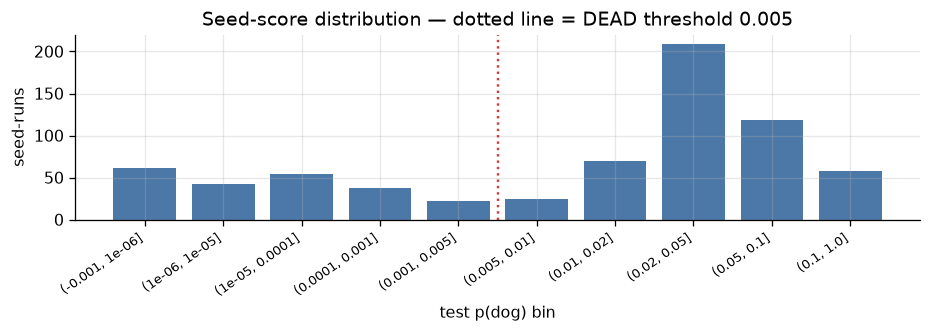

runs in the (1e-3, 5e-3] trough bin: 22 of 696
collapsed at 0.005: 217 / 696 seed-runs (31.2%)


In [4]:
# legacy trait cut — caveat: trait loss ≠ integrity collapse; operative label = anchored KL (analysis.labels)
DEAD = 0.005
EDGES = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
hist = pd.cut(runs.test, EDGES, include_lowest=True).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.2, 3.0))
ax.bar(range(len(hist)), hist.values, color="#4c78a8")
ax.set_xticks(range(len(hist)))
ax.set_xticklabels([str(i) for i in hist.index], rotation=35, ha="right", fontsize=8)
# DEAD is the right edge of its bin, so the line sits between that bar and the next
ax.axvline(hist.index.get_loc(pd.cut([DEAD], EDGES)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
ax.set_ylabel("seed-runs"); ax.set_xlabel("test p(dog) bin")
ax.set_title(f"Seed-score distribution — dotted line = DEAD threshold {DEAD}")
fig.tight_layout(); plt.show()

# Rebinds the module-level `runs` — every later section (and §9's ws1 comparisons) reads the
# `collapsed` column added here, so this cell must run before them.
runs = cl.label_collapse(runs, dead_seed=DEAD)
# Same rule, through the shared labeller, so the caveat travels with the label.
assert (labels.label_dead_trait_legacy(runs, col="test", cut=DEAD).astype(int)
        == runs.collapsed).all()
trough = runs.test.between(1e-3, 5e-3).sum()
print(f"runs in the (1e-3, 5e-3] trough bin: {trough} of {len(runs)}")
print(f"collapsed at {DEAD}: {runs.collapsed.sum()} / {len(runs)} seed-runs ({runs.collapsed.mean():.1%})")


## 3. Per-teacher student-HP grids — two cuts of the same data

Every teacher gets **two rows of panels, one after the other**:

- **View A — the house layout** (as in `cross_model_student_hp_exploration.ipynb` §8):
  y = student lr, x = LoRA **rank**, one panel per LoRA **scale $\alpha/r$**.
- **View B — the same data re-cut**: y = student lr, x = **$\alpha$**, one panel per **rank**.

Both cuts are lossless — $(\mathrm{lr}, r, \alpha/r)$ and $(\mathrm{lr}, \alpha, r)$ each pin
down a cell exactly — so they are two projections of one 3-D response, not two datasets. View A
puts the scale-vs-capacity trade-off on the page (the axis the collapse law is written in); view
B separates $\alpha$ from $r$ outright, which is the cut that makes the rank term legible now
that wave 2 has pushed rank to r32/r64. Structure that hides in one has to show up in the other.

Colour/label = mean test p(dog) on the house 0–0.2 scale, `n` = seeds. Both waves are shown
together. The grids are deliberately **sparse**: the design is a set of $K$-rungs, not a full
factorial, so most (lr, rank, α) combinations were never run and stay blank — the filled cells
trace the rungs diagonally across the panels.

**Red-boxed cells are the pre-registered prediction** — design $K \ge K^\ast$, i.e. the law says
*dead before the data existed*. The law holds exactly when red boxes contain ~0.000 and unboxed
cells don't.

8 design-dead (lr, r, α) combinations boxed in red | lr 11 x rank [4, 8, 16, 32, 64] x α [2, 4, 8, 16, 32, 64]


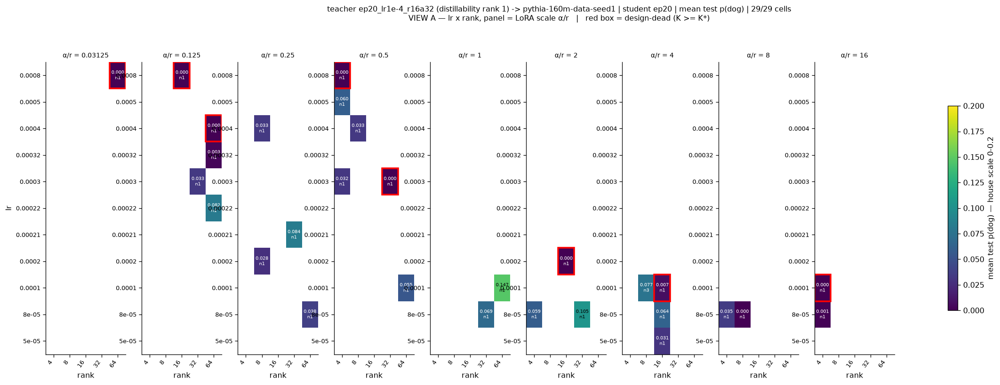

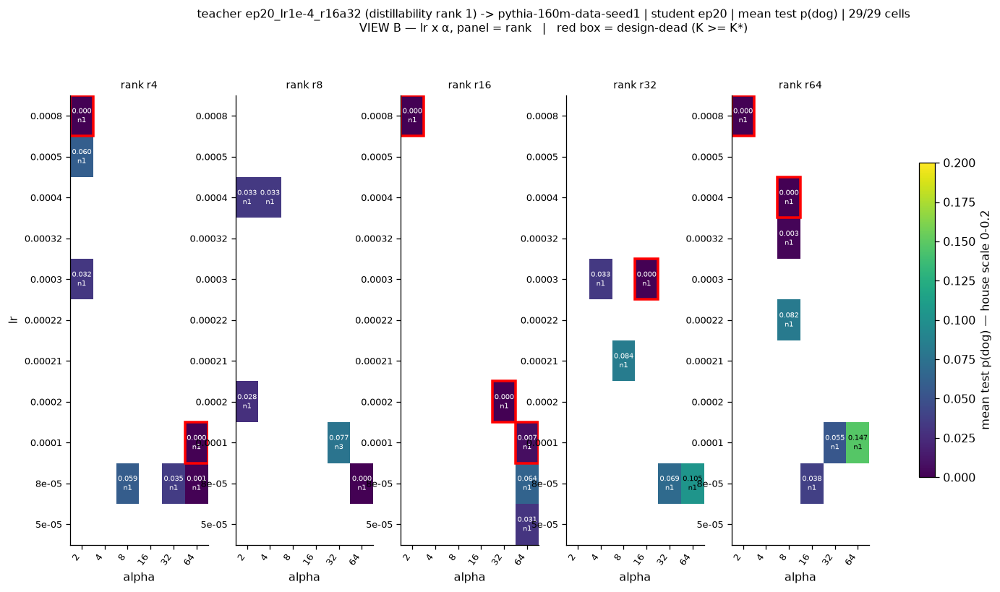

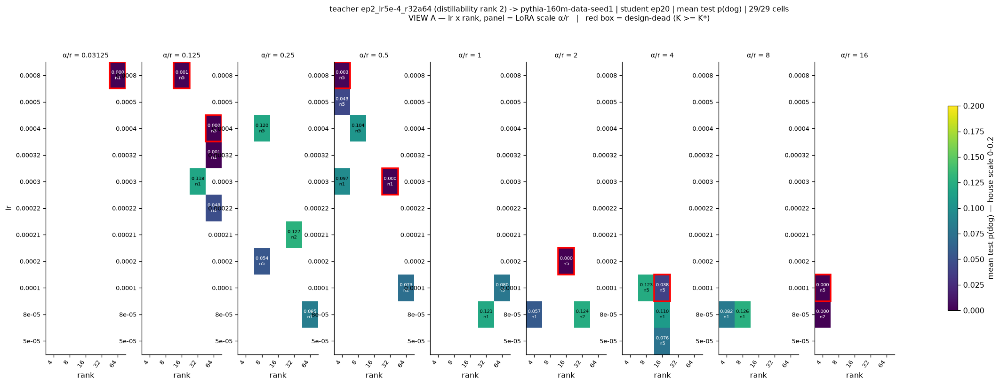

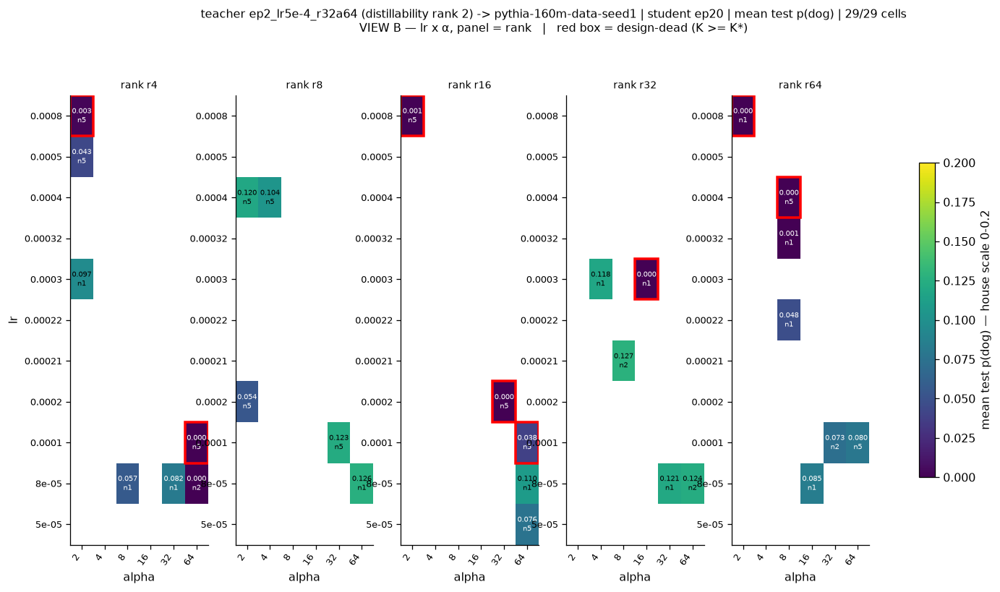

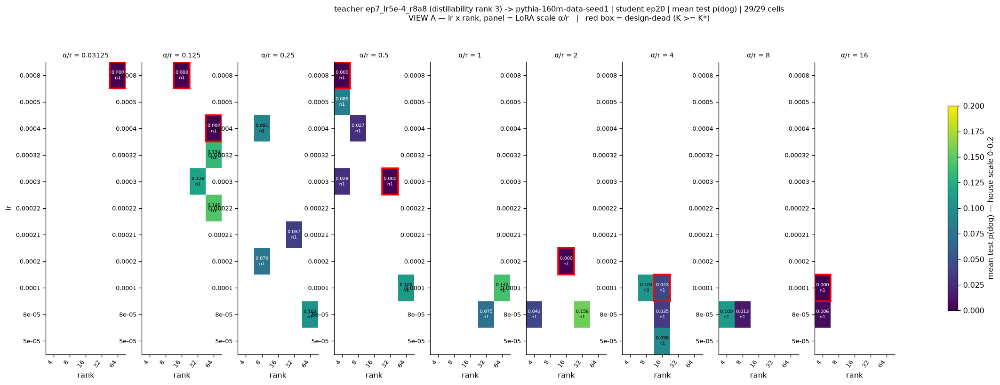

...

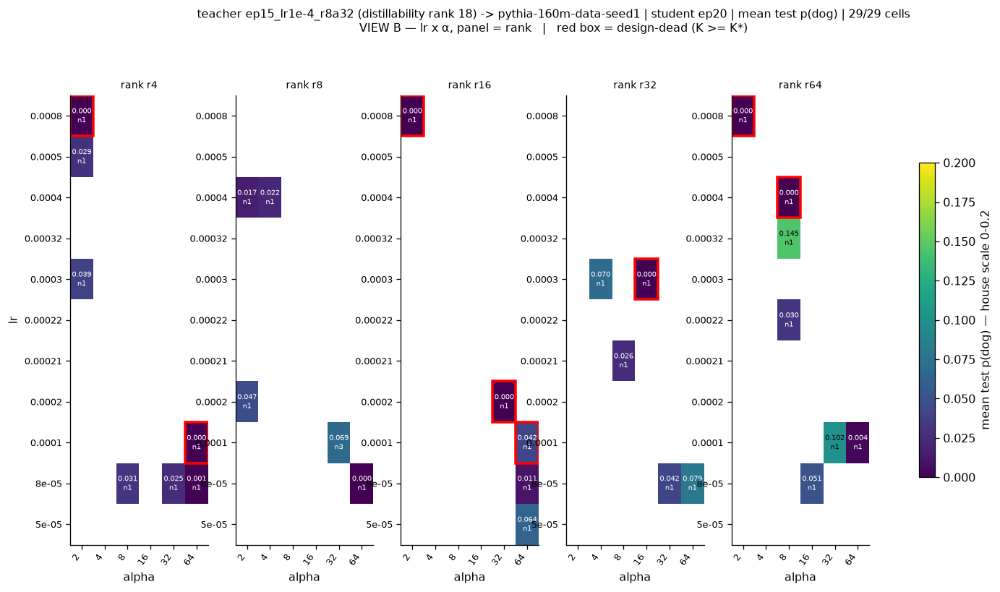

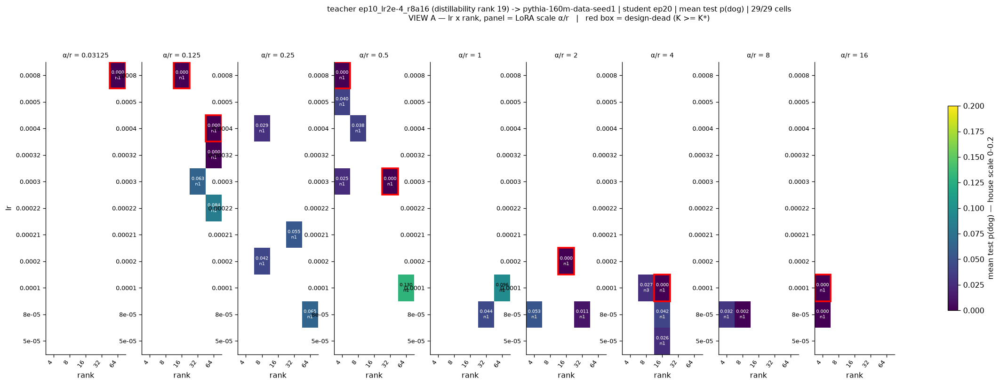

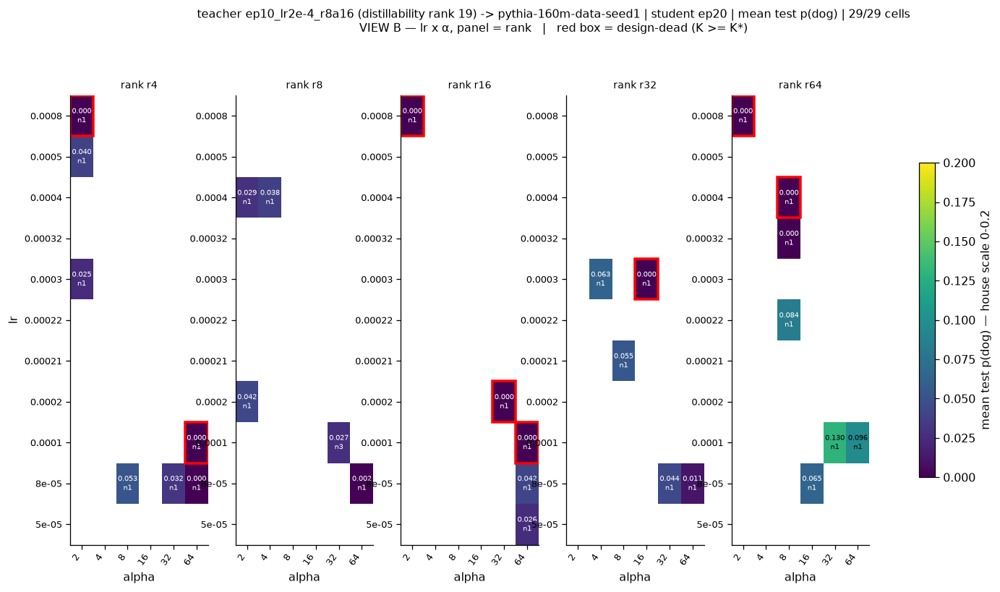

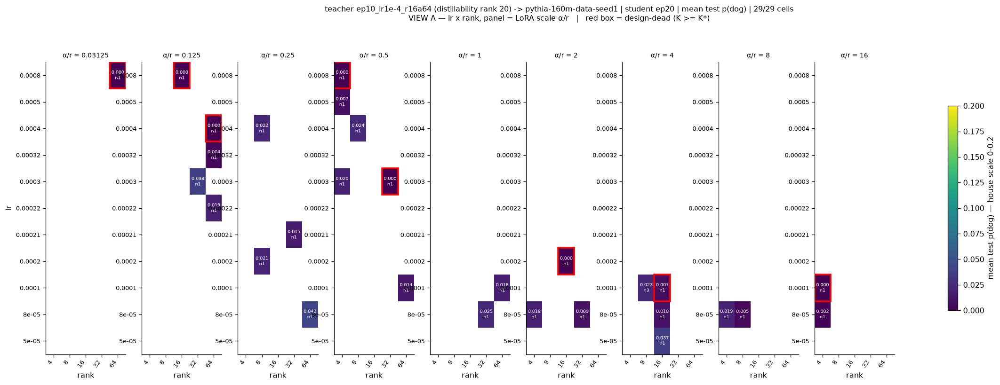

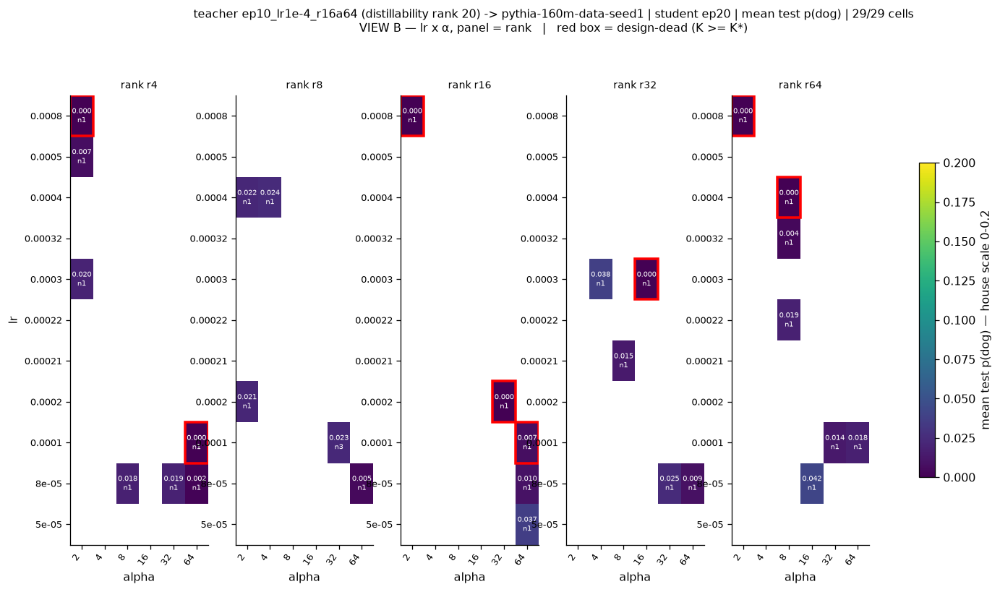

In [5]:
# Two cuts per teacher, shown one after the other. NB `highlight` dicts are keyed by the
# COLUMN NAME of each axis ("lr"/"rank"/"scale"), which is what facet_grid_heatmaps looks up
# -- the earlier literal {"row": ..., "col": ...} form silently matched nothing and drew no
# boxes at all.
LR_ORDER = sorted(runs.lr.unique())
RANK_ORDER = sorted(int(r) for r in runs["rank"].unique())
ALPHA_ORDER = sorted(int(a) for a in runs.alpha.unique())
SCALE_ORDER = sorted(float(s) for s in runs.scale.unique())

dead = (runs[runs.K >= KSTAR_DESIGN][["lr", "rank", "alpha", "scale"]].drop_duplicates())
HL_A = [{"lr": float(r.lr), "rank": int(r["rank"]), "scale": float(r.scale),
         "color": "red", "lw": 2.2} for _, r in dead.iterrows()]
HL_B = [{"lr": float(r.lr), "alpha": int(r.alpha), "rank": int(r["rank"]),
         "color": "red", "lw": 2.2} for _, r in dead.iterrows()]
print(f"{len(dead)} design-dead (lr, r, α) combinations boxed in red | "
      f"lr {len(LR_ORDER)} x rank {RANK_ORDER} x α {ALPHA_ORDER}")

for i, t in enumerate(TEACHERS, start=1):
    sub = runs[runs.teacher.eq(t)]
    if sub.empty:
        print(f"[no data yet] teacher {t} (distillability rank {i})")
        continue
    head = (f"teacher {t} (distillability rank {i}) -> {STUDENT_BASE} | student ep20 | "
            f"mean test p(dog) | {sub.student_tag.nunique()}/{len(ALL_CELLS)} cells")
    # View A — house layout: lr x rank, one panel per LoRA scale α/r.
    aplots.facet_grid_heatmaps(
        sub, row="lr", col="rank", val="test", col_facet="scale",
        agg="mean", show_n=True, panel_w=2.7, cell_fontsize=6.0,
        orders={"lr": LR_ORDER, "rank": RANK_ORDER, "scale": SCALE_ORDER},
        vmin=0.0, vmax=0.2, fmt="{:.3f}", highlight=HL_A,
        col_facet_label=lambda s: f"α/r = {s:g}",
        empty_facecolor="0.92",
        title=head + "\nVIEW A — lr x rank, panel = LoRA scale α/r   |   red box = design-dead (K >= K*)",
        cbar_label="mean test p(dog) — house scale 0-0.2")
    # View B — the same cells re-cut: lr x α, one panel per rank.
    aplots.facet_grid_heatmaps(
        sub, row="lr", col="alpha", val="test", col_facet="rank",
        agg="mean", show_n=True, panel_w=2.9,
        orders={"lr": LR_ORDER, "alpha": ALPHA_ORDER, "rank": RANK_ORDER},
        vmin=0.0, vmax=0.2, fmt="{:.3f}", highlight=HL_B,
        col_facet_label=lambda r: f"rank r{r:g}",
        empty_facecolor="0.92",
        title=head + "\nVIEW B — lr x α, panel = rank   |   red box = design-dead (K >= K*)",
        cbar_label="mean test p(dog) — house scale 0-0.2")
    plt.show()

## 4. The campaign in one matrix — rungs × teachers

**All 25 cells in a single matrix** (this is what the rank-extension section used to
duplicate). Rows are cells sorted by design $K/K^\ast$ (in parentheses); columns are the 20
teachers in distillability order. Wave-2 rank-extension rows are marked **▸ and coloured**
so the pre-registered design stays readable inside the merge — they are ordinary rows, just
labelled by provenance.

If the law transfers, the matrix splits into a live band below the dashed line
($K/K^\ast = 1$) and a dead band above it — for **every** column, *and* the wave-2 rows must
fall in with their $K$-neighbours rather than with their rank-neighbours. Red boxes mark
cells at/below the DEAD threshold.

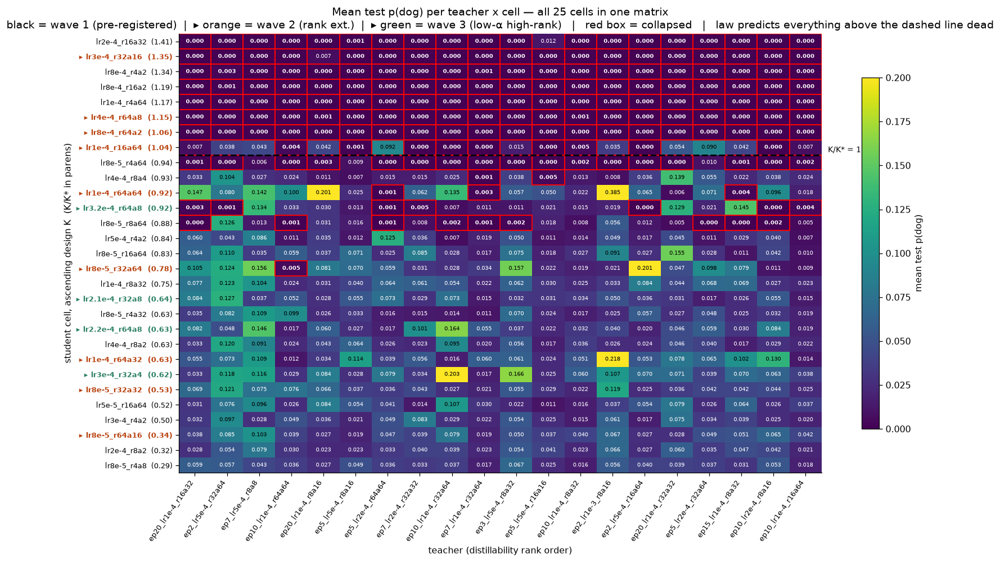

In [6]:
mat = (runs.pivot_table(index="student_tag", columns="teacher", values="test",
                        aggfunc="mean", observed=False)
       .reindex(index=CELL_ORDER, columns=TEACHERS)
       .rename(index=CELL_LABEL))
def arm_matrix(ax, grid, order, n_below, *, vmax, dead, ylabel):
    """One teacher x cell panel with this section's furniture: the K/K* = 1 rule, a red box on
    every collapsed cell, and post-wave-1 rows coloured so provenance stays visible without
    splitting the figure. Also drives §9.3's ws1 panels."""
    im = aplots.annotated_heatmap(ax, grid, vmin=0.0, vmax=vmax, fmt="{:.3f}", cell_fontsize=6,
                                  box_predicate=(lambda v: v < dead) if dead else None,
                                  box_lw=1.2)
    ax.axhline(n_below - 0.5, color="k", ls="--", lw=1.8)
    ax.text(len(TEACHERS) - 0.3, n_below - 0.45, "K/K* = 1", fontsize=9, va="bottom")
    for lbl, tag in zip(ax.get_yticklabels(), order):
        if WAVE[tag] > 1:
            lbl.set_color(WAVE_COLOR[WAVE[tag]])
            lbl.set_fontweight("bold")
    ax.set_xlabel("teacher (distillability rank order)")
    ax.set_ylabel(ylabel)
    return im


fig, ax = plt.subplots(figsize=(14.5, 8.8))
n_below = sum(design_K(t) < KSTAR_DESIGN for t in CELL_ORDER)
im = arm_matrix(ax, mat, CELL_ORDER, n_below, vmax=0.2, dead=DEAD,
                ylabel="student cell, ascending design K  (K/K* in parens)")
ax.set_title("Mean test p(dog) per teacher x cell — all 25 cells in one matrix\n"
             "black = wave 1 (pre-registered)  |  ▸ orange = wave 2 (rank ext.)  |  ▸ green = wave 3 (low-α high-rank)"
             "   |   red box = collapsed   |   law predicts everything above the dashed line dead")
fig.colorbar(im, ax=ax, shrink=0.8, label="mean test p(dog)")
fig.tight_layout(); plt.show()

## 5. The $K^\ast$ law, verified

Four tests against the pre-registered prediction, in increasing strictness:

- **(a) The pooled collapse curve.** Fraction of teachers collapsed per rung vs design
  $K/K^\ast$ — should step from ~0 to ~1 at 1.
- **(b) The pooled boundary.** `estimate_kstar` re-locates $K^\ast$ on this campaign's data
  (with the design exponents held fixed) — compare to the anchor; `law_misses` counts cells
  whose majority verdict the thresholded law gets wrong. **Reported split by wave**: wave 1
  is the clean pre-registered claim, wave 2 is held-out for the rank term (its cells were
  placed after early law-grid reads, so it does not carry pre-registration credit).
- **(c) Per-teacher boundaries.** For each complete teacher: is collapse monotone in design
  $K$ (inversions = alive/dead pairs in the wrong order), and where does its own boundary
  (geometric midpoint of the alive/dead gap) sit relative to the anchor?
- **(d) Refit.** The exponents re-estimated on this campaign alone. This is where merging the
  waves earns its keep: wave 1 spans rank 4–16, so $c$ rode on a 4× lever and its interval was
  near-useless; the merged design spans 4–64. Both fits are printed so the gain is visible.

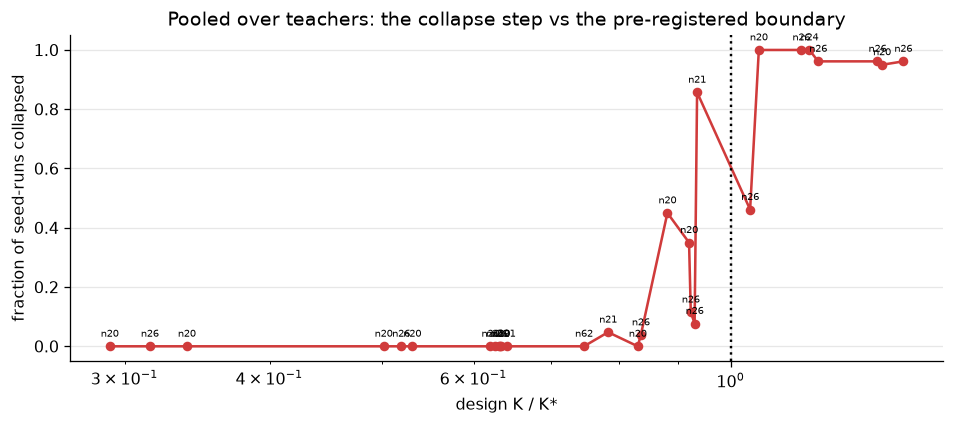

,K_rel,frac,n,p_alive
student_tag,,,,
ep20_lr8e-5_r4a8,0.291,0.000,20,0.039
ep20_lr2e-4_r8a2,0.315,0.000,26,0.041
ep20_lr8e-5_r64a16,0.339,0.000,20,0.048
ep20_lr3e-4_r4a2,0.502,0.000,20,0.041
ep20_lr5e-5_r16a64,0.519,0.000,26,0.052
ep20_lr8e-5_r32a32,0.531,0.000,20,0.051
ep20_lr3e-4_r32a4,0.620,0.000,20,0.072
ep20_lr1e-4_r64a32,0.626,0.000,21,0.068
ep20_lr4e-4_r8a2,0.631,0.000,26,0.053


In [7]:
# (a) pooled collapse curve over the rungs
rung = (runs.groupby("student_tag", observed=True)
        .agg(K_rel=("K_rel", "first"), frac=("collapsed", "mean"), n=("collapsed", "size"),
             p_alive=("test", lambda s: s[s >= DEAD].mean()))
        .reindex(CELL_ORDER))
fig, ax = plt.subplots(figsize=(8.4, 3.8))
ax.plot(rung.K_rel, rung.frac, "o-", color="#d03b3b", lw=1.6, ms=5)
for kr, fr, n in zip(rung.K_rel, rung.frac, rung.n):
    if fr == fr:  # skip not-yet-evaluated rungs (NaN)
        ax.annotate(f"n{int(n)}", (kr, fr), textcoords="offset points", xytext=(0, 6),
                    ha="center", fontsize=6.5)
ax.axvline(1.0, color="k", ls=":", lw=1.5)
ax.set(xscale="log", xlabel="design K / K*", ylabel="fraction of seed-runs collapsed",
       title="Pooled over teachers: the collapse step vs the pre-registered boundary")
fig.tight_layout(); plt.show()
display(rung.round(3))


In [8]:
# (b) pooled boundary + miss count, design exponents held fixed
ks = cl.estimate_kstar(runs, B_LAW, C_LAW)
print(f"campaign K* (geometric mean of mixed cells): {ks['kstar']:.3e} "
      f"[mixed band {ks['band'][0]:.2e} - {ks['band'][1]:.2e}, n_mixed={ks['n_mixed']}]")
print(f"design K* (law-* anchor):                    {KSTAR_DESIGN:.3e}")
if np.isfinite(ks["kstar"]):
    print(f"ratio campaign / design:                     {ks['kstar'] / KSTAR_DESIGN:.2f}x")
print(f"alive_max = {ks['alive_max']:.2e}, dead_min = {ks['dead_min']:.2e} "
      + ("(clean separation)" if ks["alive_max"] < ks["dead_min"] else "(bands overlap)"))

print("\nmajority-verdict misses when thresholding at the DESIGN K*:")
splits = [(f"all {len(ALL_CELLS)} landed cells", runs)]
splits += [(WAVE_NAME[w], runs[runs.wave.eq(w)]) for w in WAVES_PRESENT]
for name, sub in splits:
    if sub.empty:
        print(f"  {name:28s}: no data yet")
        continue
    wrong, ncells = cl.law_misses(sub, B_LAW, C_LAW, KSTAR_DESIGN)
    print(f"  {name:28s}: {wrong}/{ncells} cells misclassified")

campaign K* (geometric mean of mixed cells): 8.035e-04 [mixed band 6.14e-04 - 1.10e-03, n_mixed=12]
design K* (law-* anchor):                    7.840e-04
ratio campaign / design:                     1.02x
alive_max = 6.52e-04, dead_min = 8.29e-04 (clean separation)

majority-verdict misses when thresholding at the DESIGN K*:
  all 29 landed cells         : 2/29 cells misclassified
  wave 1 (pre-registered)     : 1/16 cells misclassified
  wave 2 (rank extension)     : 1/9 cells misclassified
  wave 3 (low-α high-rank)    : 0/4 cells misclassified


,n_dead,inversions,alive_max,dead_min,boundary,boundary_rel
teacher,,,,,,
ep20_lr1e-4_r16a32,10,7,0.0008,0.0007,0.0008,0.9571
ep2_lr5e-4_r32a64,9,4,0.0008,0.0007,0.0008,0.9778
ep7_lr5e-4_r8a8,7,0,0.0008,0.0008,0.0008,1.0480
ep10_lr1e-4_r64a64,11,8,0.0007,0.0006,0.0007,0.8539
ep20_lr1e-4_r8a16,7,7,0.0011,0.0007,0.0009,1.1236
ep5_lr5e-4_r8a16,8,0,0.0007,0.0008,0.0008,0.9857
ep5_lr2e-4_r64a64,11,7,0.0008,0.0007,0.0008,0.9571
ep7_lr2e-4_r32a32,10,2,0.0007,0.0007,0.0007,0.9254
ep10_lr1e-4_r32a64,10,3,0.0007,0.0007,0.0007,0.9057


monotone in design K (0 inversions): 3/20 complete teachers
per-teacher boundary / design K*: median 0.96, range 0.85-1.14


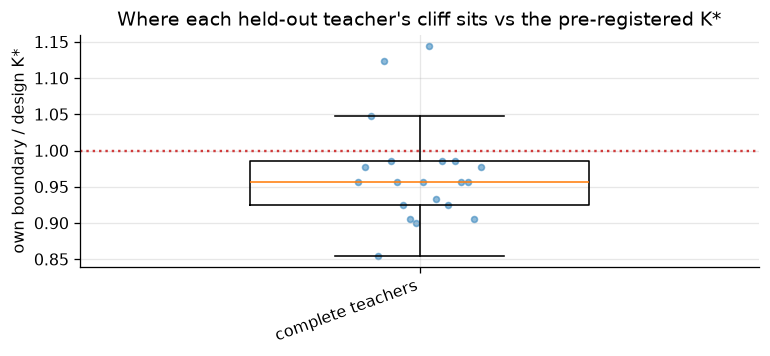

In [9]:
# (c) per-teacher monotonicity and boundary location (complete teachers only)
rows = []
for t in COMPLETE:
    d = (runs[runs.teacher.eq(t)].groupby("student_tag", observed=True)
         .agg(K=("K", "first"), frac=("collapsed", "mean")))
    dead, alive = d[d.frac >= 0.5], d[d.frac < 0.5]
    # inversions = alive/dead cell pairs ordered the wrong way round in design K
    inversions = (int((alive.K.to_numpy()[:, None] > dead.K.to_numpy()[None, :]).sum())
                  if len(dead) and len(alive) else 0)
    boundary = (float(np.sqrt(alive.K.max() * dead.K.min()))
                if len(dead) and len(alive) else np.nan)
    rows.append({"teacher": t, "n_dead": len(dead), "inversions": int(inversions),
                 "alive_max": alive.K.max() if len(alive) else np.nan,
                 "dead_min": dead.K.min() if len(dead) else np.nan,
                 "boundary": boundary,
                 "boundary_rel": boundary / KSTAR_DESIGN if boundary == boundary else np.nan})
per_t = pd.DataFrame(rows).set_index("teacher")
if len(per_t):
    display(per_t.round(4))
    clean = per_t.inversions.eq(0)
    print(f"monotone in design K (0 inversions): {clean.sum()}/{len(per_t)} complete teachers")
    b = per_t.boundary_rel.dropna()
    if len(b):
        print(f"per-teacher boundary / design K*: median {b.median():.2f}, "
              f"range {b.min():.2f}-{b.max():.2f}")
        fig, ax = plt.subplots(figsize=(6.8, 3.2))
        aplots.strip_box(ax, [b.to_numpy()], ["complete teachers"], zero_line=False)
        ax.axhline(1.0, color="#d03b3b", ls=":", lw=1.5)
        ax.set_ylabel("own boundary / design K*")
        ax.set_title("Where each held-out teacher's cliff sits vs the pre-registered K*")
        fig.tight_layout(); plt.show()
else:
    print("no complete teachers yet — re-run once the queue drains")


In [10]:
# (d) Cross-check: refit the exponents on this campaign alone (pooled, clustered on cell).
# The point of showing both fits: wave 1 alone spans rank 4-16, so c is barely identified;
# the merged design spans 4-64 at overlapping K. Watch the c interval, not b.
fits = [(f"all {len(ALL_CELLS)} landed cells  (rank "
         f"{min(map(cell_rank, ALL_CELLS))}-{max(map(cell_rank, ALL_CELLS))})", runs),
        (f"wave 1 only, {sum(1 for c in ALL_CELLS if WAVE[c] == 1)} cells  (rank 4-16)",
         runs[runs.prereg])]
for name, sub in fits:
    print(f"--- refit on {name} ---")
    if sub.empty:
        print("    no data yet")
        continue
    lab = cl.label_collapse(sub, dead_seed=DEAD)
    if lab.collapsed.nunique() != 2:
        print("    skipped: only one collapse class present")
        continue
    try:
        fit = cl.fit_collapse_law(lab)
        print(f"    b = {fit.b:+.3f} [{fit.b_ci[0]:+.3f}, {fit.b_ci[1]:+.3f}]  "
              f"design {B_LAW:+.3f}  in-CI={fit.b_ci[0] <= B_LAW <= fit.b_ci[1]}  "
              f"width {fit.b_ci[1] - fit.b_ci[0]:.3f}")
        print(f"    c = {fit.c:+.3f} [{fit.c_ci[0]:+.3f}, {fit.c_ci[1]:+.3f}]  "
              f"design {C_LAW:+.3f}  in-CI={fit.c_ci[0] <= C_LAW <= fit.c_ci[1]}  "
              f"width {fit.c_ci[1] - fit.c_ci[0]:.3f}")
        print(f"    {fit.n_runs} runs / {fit.n_cells} cells / {fit.n_dead} dead | "
              f"converged={fit.converged}")
    except Exception as e:  # near-separable designs can defeat the MLE outright
        print(f"    refit unavailable ({type(e).__name__}: {e}) — "
              "the fixed-exponent tests above stand alone")

--- refit on all 29 landed cells  (rank 4-64) ---


    b = +0.565 [+0.531, +0.599]  design +0.561  in-CI=True  width 0.069
    c = -0.097 [-0.141, -0.053]  design -0.085  in-CI=True  width 0.088
    696 runs / 29 cells / 217 dead | converged=True
--- refit on wave 1 only, 16 cells  (rank 4-16) ---
    b = +0.600 [+0.581, +0.619]  design +0.561  in-CI=False  width 0.039
    c = -0.148 [-0.210, -0.085]  design -0.085  in-CI=False  width 0.125
    415 runs / 16 cells / 129 dead | converged=True


## 6. Signal vs distance to the cliff

The law-* campaign found transfer *peaks just below* the boundary ($K/K^\ast \approx
0.5$–$1$) then dies past it. Same read here: mean p(dog) among surviving seed-runs by
$K/K^\ast$ band — pooled, and per complete teacher (normalised, since levels differ
across teachers).


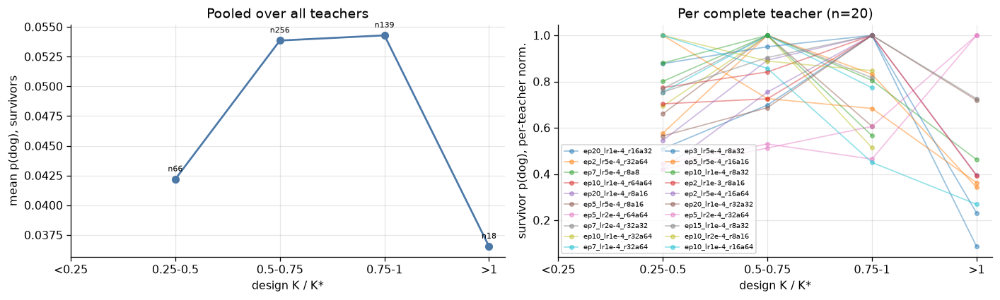

In [11]:
alive = runs[runs.collapsed.eq(0)].copy()
alive["band"] = pd.cut(alive.K_rel, [0, .25, .5, .75, 1.0, 1e9],
                       labels=["<0.25", "0.25-0.5", "0.5-0.75", "0.75-1", ">1"])
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.8))
pooled = alive.groupby("band", observed=False).test.agg(["mean", "size"])
axes[0].plot(range(len(pooled)), pooled["mean"], "o-", color="#4c78a8", lw=1.7)
for i, (m, n) in enumerate(zip(pooled["mean"], pooled["size"])):
    if n:
        axes[0].annotate(f"n{n}", (i, m), textcoords="offset points", xytext=(0, 7),
                         ha="center", fontsize=7)
axes[0].set_xticks(range(len(pooled))); axes[0].set_xticklabels(pooled.index)
axes[0].set_xlabel("design K / K*"); axes[0].set_ylabel("mean p(dog), survivors")
axes[0].set_title("Pooled over all teachers")
for t in COMPLETE:
    m = alive[alive.teacher.eq(t)].groupby("band", observed=False).test.mean()
    if m.notna().any():
        axes[1].plot(range(len(m)), m / m.max(), "o-", alpha=0.45, lw=1.1, ms=3.5, label=t)
axes[1].set_xticks(range(len(pooled))); axes[1].set_xticklabels(pooled.index)
axes[1].set_xlabel("design K / K*"); axes[1].set_ylabel("survivor p(dog), per-teacher norm.")
axes[1].set_title(f"Per complete teacher (n={len(COMPLETE)})")
if COMPLETE:
    axes[1].legend(fontsize=6, ncol=2)
fig.tight_layout(); plt.show()


## 7. High rank at matched $K$ — is $K$ sufficient?

Wave 2 exists to test the rank term, and the identifying contrast is **fixed $K$, different
rank**: the high-rank cells re-realize existing rungs at r32/r64, so rank moves 4–16× while
design $K$ is held (within `TWIN_TOL` = 12%). Under the law a cell's fate depends on $K$
*only*, so each high-rank twin must behave exactly like its low-rank rung-mates.

Two separable questions, and they do **not** get the same answer:

- **(i) The binary verdict** — does the high-rank twin *collapse* when its rung-mates do?
- **(ii) The magnitude** — among survivors, does it reach the *same* p(dog)?

*Caveat on the matching.* Near the cliff the collapse fraction moves from ~0 to ~1 across a
few percent in $K$, so a ±12% match window there spans the whole transition. Rungs whose
matched low-rank set straddles $K/K^\ast = 1$ are flagged `straddles`, and the headline gap
is reported with and without them — a gap at a straddling rung measures the tolerance, not
the rank effect.

The cells themselves are no longer segregated — they are in the §3 grids, the §4 matrix and
the §5 fits like any others. What remains here is the *contrast* those cells were built to
support.

> **Why the fixed-$(\mathrm{lr}, \alpha)$ rank ladders were dropped.** Inside a ladder lr and
> $\alpha$ are held fixed, so $K \propto r^{c}$ — design $K$ and rank are *perfectly
> collinear*. Such a ladder cannot separate "the law's rank term" from any other rank effect;
> it tests a joint prediction (cross the cliff by raising rank alone) but identifies nothing,
> and reading it as an estimate of $c$ would be circular. The merged 25-cell design does the
> job properly: rank spans 4–64 at *overlapping* $K$, which is exactly what lets §5d put a
> real interval on $c$. All three former ladder cells are still in the frame — they simply
> enter as ordinary cells.

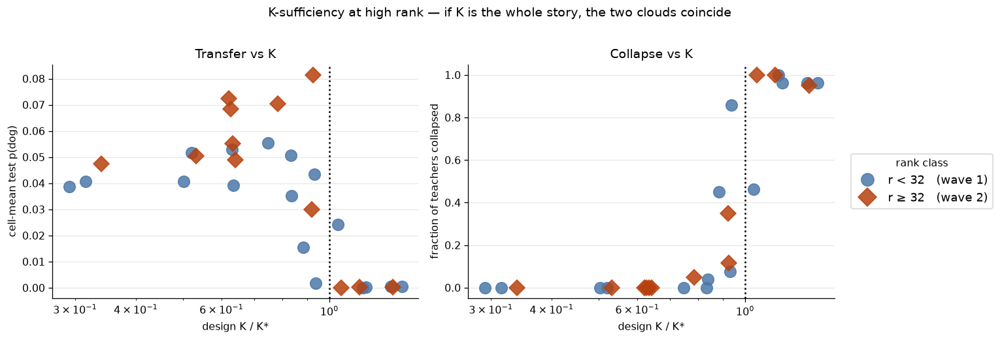

In [12]:
# (a) K-sufficiency: every cell on one K axis, split by rank class. If K is the whole
# story the two clouds trace the SAME curve — no vertical offset at matched K.
cm = (runs.groupby("student_tag", observed=True)
      .agg(K_rel=("K_rel", "first"), p=("test", "mean"), frac=("collapsed", "mean"),
           rank=("rank", "first"), n=("test", "size"))
      .reset_index())
cm["hi"] = cm["rank"] >= HI_RANK

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.4))
for hi, color, mk, label in [(False, "#4c78a8", "o", f"r < {HI_RANK}   (wave 1)"),
                             (True, EXT_COLOR, "D", f"r ≥ {HI_RANK}   (wave 2)")]:
    d = cm[cm.hi.eq(hi)]
    axes[0].plot(d.K_rel, d.p, mk, color=color, ms=11, alpha=0.85, label=label)
    axes[1].plot(d.K_rel, d.frac, mk, color=color, ms=11, alpha=0.85, label=label)
for ax, ylab, title in [(axes[0], "cell-mean test p(dog)", "Transfer vs K"),
                        (axes[1], "fraction of teachers collapsed", "Collapse vs K")]:
    ax.axvline(1.0, color="k", ls=":", lw=1.6)
    ax.set(xscale="log", xlabel="design K / K*", ylabel=ylab, title=title)
axes[1].legend(fontsize=11, loc="center left", bbox_to_anchor=(1.03, 0.5),
               frameon=True, markerscale=1.1, title="rank class")
fig.suptitle("K-sufficiency at high rank — if K is the whole story, the two clouds coincide",
             y=1.02)
fig.tight_layout(); plt.show()

,K_rel,hi_cell,hi_rank,lo_cells,lo_K_min,lo_K_max,straddles,n_teachers,collapse_hi,collapse_lo,d_collapse,p_hi,p_lo,hi_alive_lo_dead,hi_dead_lo_alive
0,0.339,lr8e-5_r64a16,64,lr2e-4_r8a2,0.315,0.315,False,20,0.00,0.000,0.000,0.048,0.039,0,0
1,0.531,lr8e-5_r32a32,32,"lr3e-4_r4a2, lr5e-5_r16a64",0.502,0.519,False,20,0.00,0.000,0.000,0.051,0.044,0,0
2,0.620,lr3e-4_r32a4,32,"lr4e-4_r8a2, lr8e-5_r4a32",0.631,0.634,False,20,0.00,0.000,0.000,0.072,0.041,0,0
3,0.626,lr1e-4_r64a32,64,"lr4e-4_r8a2, lr8e-5_r4a32",0.631,0.634,False,20,0.00,0.000,0.000,0.068,0.041,0,0
4,0.633,lr2.2e-4_r64a8,64,"lr4e-4_r8a2, lr8e-5_r4a32",0.631,0.634,False,20,0.00,0.000,0.000,0.055,0.041,0,0
5,0.641,lr2.1e-4_r32a8,32,"lr4e-4_r8a2, lr8e-5_r4a32",0.631,0.634,False,20,0.00,0.000,0.000,0.045,0.041,0,0
6,0.784,lr8e-5_r32a64,32,"lr1e-4_r8a32, lr8e-5_r16a64, lr5e-4_r4a2",0.747,0.836,False,20,0.05,0.007,0.043,0.068,0.048,0,1
7,0.920,lr3.2e-4_r64a8,64,"lr8e-5_r16a64, lr5e-4_r4a2, lr8e-5_r8a64, lr4e...",0.831,0.935,False,20,0.35,0.278,0.072,0.030,0.027,1,7
8,0.923,lr1e-4_r64a64,64,"lr8e-5_r16a64, lr5e-4_r4a2, lr8e-5_r8a64, lr4e...",0.831,0.935,False,20,0.15,0.278,-0.128,0.083,0.027,0,2
9,1.057,lr8e-4_r64a2,64,"lr4e-4_r8a4, lr8e-5_r4a64, lr1e-4_r4a64",0.931,1.169,True,20,1.00,0.632,0.368,0.000,0.012,0,4


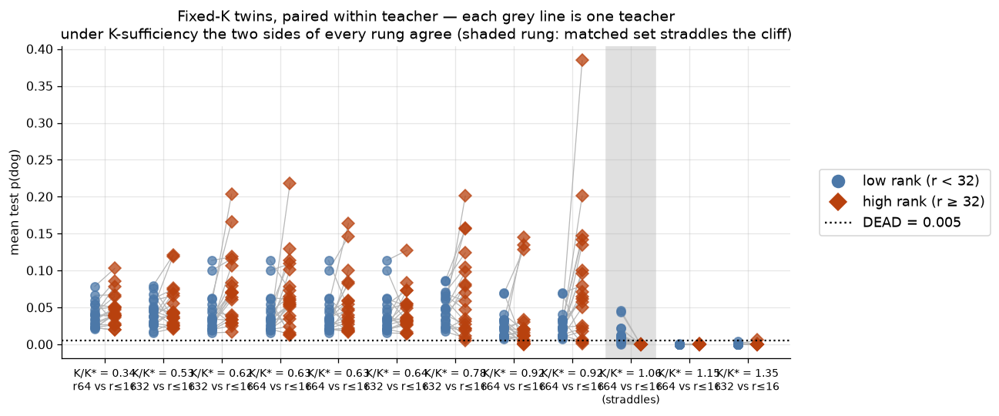

(i) VERDICT — 240 paired teacher-rungs over 12 twin rungs (11 not straddling the cliff)
    verdict agreement: 224/240 (93.3%) | high-rank alive where low dead: 2, reverse: 14
    mean paired collapse gap (high - low): all rungs +0.028, excluding straddling rungs -0.003
    (0 = K sufficient; negative = rank MORE protective than c = -0.085 implies)

(ii) MAGNITUDE — among 168 pairs alive on BOTH sides:
     median p(high) / p(low) = 1.38x  (mean log2 ratio +0.45); high-rank higher in 114/168 pairs (68%)
     per-rung mean p, high vs low: 0.34: 0.048 vs 0.039 | 0.53: 0.051 vs 0.044 | 0.62: 0.072 vs 0.041 | 0.63: 0.068 vs 0.041 | 0.63: 0.055 vs 0.041 | 0.64: 0.045 vs 0.041 | 0.78: 0.068 vs 0.048 | 0.92: 0.030 vs 0.027 | 0.92: 0.083 vs 0.027 | 1.06: 0.000 vs 0.012 | 1.15: 0.000 vs 0.000 | 1.35: 0.000 vs 0.000
     A ratio systematically above 1 means K is sufficient for WHETHER a cell collapses
     but not for HOW MUCH transfer survives — rank buys headroom the scalar K cannot carry.


In [13]:
# (b) The identifying test: each high-rank cell against its matched-K wave-1 rung-mates,
# PAIRED WITHIN TEACHER, so teacher quality cancels. Under K-sufficiency the paired
# differences scatter around zero at every rung.
pair_rows, summary = [], []
for hi, los in sorted(TWINS.items(), key=lambda kv: design_K(kv[0])):
    d_hi = (runs[runs.student_tag.eq(hi)].groupby("teacher", observed=True)
            .agg(p_hi=("test", "mean"), col_hi=("collapsed", "mean")))
    d_lo = (runs[runs.student_tag.isin(los)].groupby("teacher", observed=True)
            .agg(p_lo=("test", "mean"), col_lo=("collapsed", "mean")))
    j = d_hi.join(d_lo, how="inner").dropna()
    if j.empty:
        continue
    lo_k = [design_K(l) / KSTAR_DESIGN for l in los]
    # A matched set spanning K/K* = 1 sits inside the transition, where a 12% window is the
    # whole cliff — its gap measures the tolerance, not rank. Flag it, don't hide it.
    straddles = min(lo_k) < 1.0 <= max(lo_k)
    pair_rows.append(j.reset_index().assign(hi_cell=hi, straddles=straddles))
    summary.append({
        "K_rel": design_K(hi) / KSTAR_DESIGN,
        "hi_cell": hi.removeprefix("ep20_"), "hi_rank": cell_rank(hi),
        "lo_cells": ", ".join(l.removeprefix("ep20_") for l in los),
        "lo_K_min": min(lo_k), "lo_K_max": max(lo_k), "straddles": straddles,
        "n_teachers": len(j),
        "collapse_hi": j.col_hi.mean(), "collapse_lo": j.col_lo.mean(),
        "d_collapse": j.col_hi.mean() - j.col_lo.mean(),
        "p_hi": j.p_hi.mean(), "p_lo": j.p_lo.mean(),
        "hi_alive_lo_dead": int(((j.col_hi < 0.5) & (j.col_lo >= 0.5)).sum()),
        "hi_dead_lo_alive": int(((j.col_hi >= 0.5) & (j.col_lo < 0.5)).sum()),
    })

tw = pd.DataFrame(summary)
if tw.empty:
    print("no fixed-K twin pairs evaluated yet — re-run once wave 2 lands")
else:
    display(tw.round(3))
    pairs = pd.concat(pair_rows, ignore_index=True)
    fig, ax = plt.subplots(figsize=(11.4, 4.8))
    for i, (_, row) in enumerate(tw.iterrows()):
        d = pairs[pairs.hi_cell.eq("ep20_" + row.hi_cell)]
        for _, r2 in d.iterrows():          # the pairing line is the point of the plot
            ax.plot([i - 0.17, i + 0.17], [r2.p_lo, r2.p_hi], color="0.72", lw=0.8, zorder=0)
        ax.plot(np.full(len(d), i - 0.17), d.p_lo, "o", color="#4c78a8", ms=7, alpha=0.75)
        ax.plot(np.full(len(d), i + 0.17), d.p_hi, "D", color=EXT_COLOR, ms=7, alpha=0.75)
        if row.straddles:                   # mark the untrustworthy rung in the figure too
            ax.axvspan(i - 0.42, i + 0.42, color="0.88", zorder=-5)
    ax.axhline(DEAD, color="k", ls=":", lw=1.4)
    ax.set_xticks(range(len(tw)))
    ax.set_xticklabels([f"K/K* = {k:.2f}\nr{int(r)} vs r≤16" + ("\n(straddles)" if s else "")
                        for k, r, s in zip(tw.K_rel, tw.hi_rank, tw.straddles)], fontsize=9)
    ax.set_ylabel("mean test p(dog)")
    ax.set_title("Fixed-K twins, paired within teacher — each grey line is one teacher\n"
                 "under K-sufficiency the two sides of every rung agree "
                 "(shaded rung: matched set straddles the cliff)")
    handles = [plt.Line2D([], [], marker="o", ls="", color="#4c78a8", ms=10,
                          label=f"low rank (r < {HI_RANK})"),
               plt.Line2D([], [], marker="D", ls="", color=EXT_COLOR, ms=10,
                          label=f"high rank (r ≥ {HI_RANK})"),
               plt.Line2D([], [], ls=":", color="k", label=f"DEAD = {DEAD}")]
    ax.legend(handles=handles, fontsize=11, loc="center left", bbox_to_anchor=(1.03, 0.5),
              frameon=True)
    fig.tight_layout(); plt.show()

    # ---- (i) the binary verdict -------------------------------------------------------
    clean = tw[~tw.straddles]
    n_pairs = int(tw.n_teachers.sum())
    n_dis = int(tw.hi_alive_lo_dead.sum() + tw.hi_dead_lo_alive.sum())
    print(f"(i) VERDICT — {n_pairs} paired teacher-rungs over {len(tw)} twin rungs "
          f"({len(clean)} not straddling the cliff)")
    print(f"    verdict agreement: {n_pairs - n_dis}/{n_pairs} ({1 - n_dis / n_pairs:.1%}) | "
          f"high-rank alive where low dead: {int(tw.hi_alive_lo_dead.sum())}, "
          f"reverse: {int(tw.hi_dead_lo_alive.sum())}")
    print(f"    mean paired collapse gap (high - low): all rungs {tw.d_collapse.mean():+.3f}, "
          f"excluding straddling rungs {clean.d_collapse.mean():+.3f}")
    print("    (0 = K sufficient; negative = rank MORE protective than c = -0.085 implies)")

    # ---- (ii) the magnitude among survivors -------------------------------------------
    both_alive = pairs[(pairs.col_hi < 0.5) & (pairs.col_lo < 0.5)
                       & (pairs.p_hi > 0) & (pairs.p_lo > 0)]
    if len(both_alive):
        lr_ratio = np.log2(both_alive.p_hi / both_alive.p_lo)
        n_up = int((lr_ratio > 0).sum())
        print(f"\n(ii) MAGNITUDE — among {len(both_alive)} pairs alive on BOTH sides:")
        print(f"     median p(high) / p(low) = {2 ** lr_ratio.median():.2f}x  "
              f"(mean log2 ratio {lr_ratio.mean():+.2f}); high-rank higher in "
              f"{n_up}/{len(lr_ratio)} pairs ({n_up / len(lr_ratio):.0%})")
        print("     per-rung mean p, high vs low: "
              + " | ".join(f"{k:.2f}: {h:.3f} vs {l:.3f}"
                           for k, h, l in zip(tw.K_rel, tw.p_hi, tw.p_lo)))
        print("     A ratio systematically above 1 means K is sufficient for WHETHER a cell "
              "collapses\n     but not for HOW MUCH transfer survives — rank buys headroom the "
              "scalar K cannot carry.")

In [14]:
# (c) Rung-level ledger: every design cell, its realization, and predicted vs observed
# verdict. This is the §4 matrix collapsed to one row per cell — the heatmap itself now
# lives in §4 rather than being duplicated here.
rungs = (runs.groupby("student_tag", observed=True)
         .agg(K_rel=("K_rel", "first"), lr=("lr", "first"), alpha=("alpha", "first"),
              rank=("rank", "first"), frac_collapsed=("collapsed", "mean"),
              mean_p=("test", "mean"), n_teachers=("teacher", "nunique"))
         .reindex(CELL_ORDER))
rungs.insert(0, "wave", [WAVE[t] for t in rungs.index])
rungs.insert(1, "scale", rungs.alpha / rungs["rank"])
rungs["predicted"] = np.where(rungs.K_rel >= 1, "dead", "alive")
rungs["observed"] = np.where(rungs.frac_collapsed >= 0.5, "dead", "alive")
rungs["miss"] = np.where(rungs.predicted.ne(rungs.observed) & rungs.frac_collapsed.notna(),
                         "<-- MISS", "")
display(rungs.round(3))

,wave,scale,K_rel,lr,alpha,rank,frac_collapsed,mean_p,n_teachers,predicted,observed,miss
student_tag,,,,,,,,,,,,
ep20_lr8e-5_r4a8,1,2.000,0.291,0.000,8,4,0.000,0.039,20,alive,alive,
ep20_lr2e-4_r8a2,1,0.250,0.315,0.000,2,8,0.000,0.041,20,alive,alive,
ep20_lr8e-5_r64a16,2,0.250,0.339,0.000,16,64,0.000,0.048,20,alive,alive,
ep20_lr3e-4_r4a2,1,0.500,0.502,0.000,2,4,0.000,0.041,20,alive,alive,
ep20_lr5e-5_r16a64,1,4.000,0.519,0.000,64,16,0.000,0.052,20,alive,alive,
ep20_lr8e-5_r32a32,2,1.000,0.531,0.000,32,32,0.000,0.051,20,alive,alive,
ep20_lr3e-4_r32a4,3,0.125,0.620,0.000,4,32,0.000,0.072,20,alive,alive,
ep20_lr1e-4_r64a32,2,0.500,0.626,0.000,32,64,0.000,0.068,20,alive,alive,
ep20_lr4e-4_r8a2,1,0.250,0.631,0.000,2,8,0.000,0.053,20,alive,alive,


## 8. Teacher-level summary

Best cell per teacher and its location relative to the boundary, in distillability order —
the existence-arm headline: what is the best cross-init transfer a top teacher can reach, and
does the optimum sit where the law says it should (just under the cliff)? The `wave` column
records whether the winner is a pre-registered or a rank-extension cell; wave-2 cells winning
more often than their 9/25 share would be evidence that high rank buys real headroom.

,best_cell,wave,best_p,best_K_rel,n,mean_alive_p
teacher,,,,,,
ep20_lr1e-4_r16a32,ep20_lr1e-4_r64a64,2,0.147,0.923,1,0.056
ep2_lr5e-4_r32a64,ep20_lr2.1e-4_r32a8,3,0.127,0.641,2,0.090
ep7_lr5e-4_r8a8,ep20_lr8e-5_r32a64,2,0.156,0.784,1,0.081
ep10_lr1e-4_r64a64,ep20_lr1e-4_r64a64,2,0.100,0.923,1,0.041
ep20_lr1e-4_r8a16,ep20_lr1e-4_r64a64,2,0.201,0.923,1,0.047
ep5_lr5e-4_r8a16,ep20_lr1e-4_r64a32,2,0.114,0.626,1,0.038
ep5_lr2e-4_r64a64,ep20_lr5e-4_r4a2,1,0.125,0.836,1,0.049
ep7_lr2e-4_r32a32,ep20_lr2.2e-4_r64a8,3,0.101,0.633,1,0.042
ep10_lr1e-4_r32a64,ep20_lr3e-4_r32a4,3,0.203,0.620,1,0.061


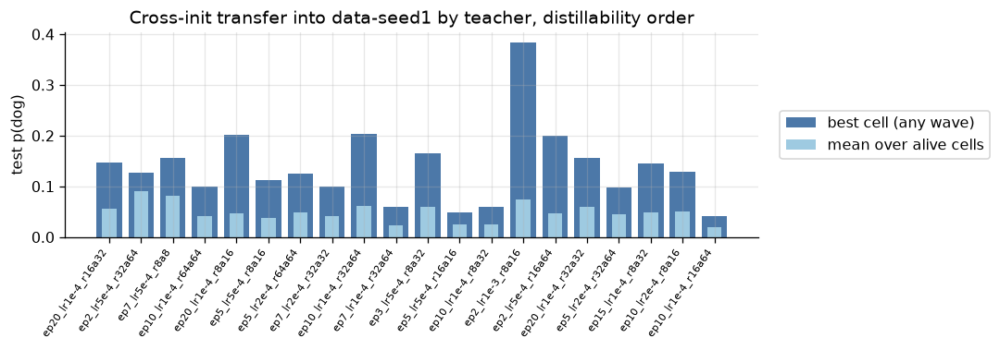

best cells sit at K/K*: median 0.78, range 0.34-0.92
best cell by wave: w1=2/20 teachers (w1 is 16/29 of the cells), w2=12/20 teachers (w2 is 9/29 of the cells), w3=6/20 teachers (w3 is 4/29 of the cells)


In [15]:
cellmeans = (runs.groupby(["teacher", "student_tag"], observed=True)
             .agg(p=("test", "mean"), K_rel=("K_rel", "first"), n=("test", "size"))
             .reset_index())
best = (cellmeans.sort_values("p").groupby("teacher", observed=False).tail(1)
        .set_index("teacher").reindex(TEACHERS)
        .rename(columns={"student_tag": "best_cell", "p": "best_p", "K_rel": "best_K_rel"}))
best.insert(1, "wave", best.best_cell.map(WAVE))
best["mean_alive_p"] = (cellmeans[cellmeans.p >= DEAD]
                        .groupby("teacher", observed=False).p.mean())
display(best.round(3))

fig, ax = plt.subplots(figsize=(9.6, 3.4))
x = np.arange(len(TEACHERS))
ax.bar(x, best.best_p, color="#4c78a8", label="best cell (any wave)")
ax.bar(x, best.mean_alive_p, color="#9ecae1", width=0.45, label="mean over alive cells")
ax.set_xticks(x); ax.set_xticklabels(TEACHERS, rotation=55, ha="right", fontsize=7)
ax.set_ylabel("test p(dog)")
ax.legend(fontsize=10, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True)
ax.set_title("Cross-init transfer into data-seed1 by teacher, distillability order")
fig.tight_layout(); plt.show()
if best.best_K_rel.notna().any():
    print(f"best cells sit at K/K*: median {best.best_K_rel.median():.2f}, "
          f"range {best.best_K_rel.min():.2f}-{best.best_K_rel.max():.2f}")
    share = {w: sum(1 for c in ALL_CELLS if WAVE[c] == w) for w in WAVES_PRESENT}
    print("best cell by wave: "
          + ", ".join(f"w{w}={int((best.wave == w).sum())}/{len(TEACHERS)} teachers "
                      f"(w{w} is {share[w]}/{len(ALL_CELLS)} of the cells)"
                      for w in WAVES_PRESENT))

## 9. The `weight-seed1` arm — the same cells on the other student init

**The `top20-krungs-ws1` campaign (drained 2026-07-30, 500/500, zero failures).** The same 20
teachers and the same **wave-1 + wave-2 cells (25 in total)** are cross-distilled into the
**weight-seed1** student base. Wave 3 (the low-$\alpha$ high-rank extension) was never queued on
this arm, so §9 covers waves 1–2 only.

Two things make this a genuine out-of-sample test rather than a repeat:

1. **A different init, so a different anchor.** The `law-*` campaign fits $K^\ast$ per
   (teacher family × student init). `KSTAR_DESIGN` above is the mean of its three *data*-seed1
   arms; the weight-seed1 anchor is the mean of its three *weight*-seed1 arms, and it is
   **lower** — weight-seed1 students collapse at a smaller $K$.
2. **The cells were placed on the ds1 grid.** The ws1 queue reuses the ds1 tags verbatim, so
   relative to its *own* anchor this arm samples a band shifted **up** by
   $K^\ast_{ds1}/K^\ast_{ws1}$. That is not a design flaw — it buys reach past the cliff — but it
   means a larger share of ws1 cells is dead *by construction*, and any raw
   "ws1 collapses more" statement has to be read against the shifted axis, not as a property
   of the init.

The arm is loaded into its own frame (`wsr`) so §1–8 stay exactly as they were.

In [16]:
# ---------------------------------------------------------------------------------------
# Load the weight-seed1 arm. Same loader, same 20 lineages, different student base.
# ---------------------------------------------------------------------------------------
STUDENT_BASE_WS = "pythia-160m-weight-seed1"

# Per-arm K* from the law-* campaign (collapse_law_generality.ipynb §5 fit table). The two
# notebook anchors are the within-init means of those six arms, so they are constructed the
# same way -- KSTAR_DESIGN below is reproduced from its parts as a check on the provenance.
KSTAR_DS1_ARMS = {"focus": 8.91e-4, "strong": 7.94e-4, "weak": 6.66e-4}
KSTAR_WS1_ARMS = {"focus": 7.79e-4, "strong": 6.60e-4, "weak": 6.35e-4}
KSTAR_WS1 = float(np.mean(list(KSTAR_WS1_ARMS.values())))
assert abs(np.mean(list(KSTAR_DS1_ARMS.values())) / KSTAR_DESIGN - 1) < 0.005, "ds1 anchor provenance"

# Wave 3 was never submitted on this arm -- the ws1 queue is waves 1+2 only.
WS_DESIGN = CAMPAIGN_CELLS + RANK_PROBE_CELLS

cells_ws_all, runs_ws_all = cl.load_law_runs(
    OUTPUT_ROOT, lineages=[(t, t, STUDENT_BASE_WS) for t in TEACHERS])
runs_ws_all.rename(columns={"family": "teacher"}, inplace=True)

present_ws = set(runs_ws_all.student_tag)
WS_CELLS = [c for c in WS_DESIGN if c in present_ws]
WS_PENDING = [c for c in WS_DESIGN if c not in present_ws]

wsr = build_arm(runs_ws_all, WS_CELLS, KSTAR_WS1)   # K_rel normalised by THIS init's anchor
wsr["K_rel_ds"] = wsr["K"] / KSTAR_DESIGN           # ... and by the grid the cells were placed on

WS_CELL_ORDER = list(pd.Series({t: design_K(t) for t in WS_CELLS}).sort_values().index)
shift = KSTAR_DESIGN / KSTAR_WS1

print(f"ws1 anchor K* = {KSTAR_WS1:.3e}  vs  ds1 anchor {KSTAR_DESIGN:.3e}   "
      f"({KSTAR_WS1 / KSTAR_DESIGN:.2f}x -- weight-seed1 collapses earlier)")
print(f"cells on disk: {len(WS_CELLS)}/{len(WS_DESIGN)} (waves 1-2)"
      + (f" | NOT YET RUN: {', '.join(c.removeprefix('ep20_') for c in WS_PENDING)}"
         if WS_PENDING else " | all ws1 design cells present"))
print(f"seed-runs {len(wsr)} across {wsr.teacher.nunique()} teachers | "
      f"seeds per cell: min {wsr.groupby(['teacher', 'student_tag'], observed=True).size().min()}, "
      f"max {wsr.groupby(['teacher', 'student_tag'], observed=True).size().max()}")
print(f"\nthe placement shift: cells span K/K* {wsr.K_rel_ds.min():.2f}-{wsr.K_rel_ds.max():.2f} "
      f"on the ds1 grid they were placed on,")
print(f"                     but K/K* {wsr.K_rel.min():.2f}-{wsr.K_rel.max():.2f} against the "
      f"ws1 anchor -- everything sits {shift:.2f}x higher.")

ws1 anchor K* = 6.913e-04  vs  ds1 anchor 7.840e-04   (0.88x -- weight-seed1 collapses earlier)
cells on disk: 25/25 (waves 1-2) | all ws1 design cells present
seed-runs 552 across 20 teachers | seeds per cell: min 1, max 3

the placement shift: cells span K/K* 0.29-1.41 on the ds1 grid they were placed on,
                     but K/K* 0.33-1.60 against the ws1 anchor -- everything sits 1.13x higher.


### 9.1 The threshold, re-checked on *this* arm

§2 set `DEAD = 0.005` from the trough of the ds1 distribution, with the explicit caveat that a
threshold must not be inherited blind. That caveat bites here: the ws1 seed-score distribution
is **less cleanly bimodal** — its live mode is compressed toward zero (the whole arm transfers
more weakly), so the empty trough sits *lower* and is *shallower* than ds1's.

The sensitivity table is the point of this cell, not the single number: on ds1 the boundary
estimate is flat across the whole plausible threshold range, while on ws1 it is not. Reporting
ws1 at ds1's threshold would manufacture a law failure that is really a thresholding artefact.

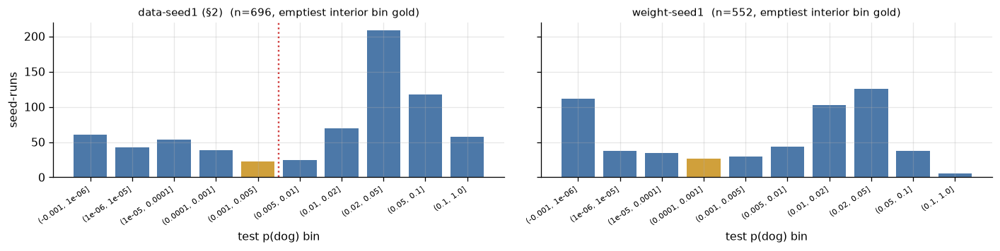

collapsed_frac campaign_Kstar  ratio_to_anchor misses
arm          DEAD                                                        
data-seed1   0.001           0.280       8.74e-04             1.11   2/29
             0.002           0.290       8.42e-04             1.07   2/29
             0.005           0.312       8.04e-04             1.02   2/29
             0.010           0.346       7.43e-04             0.95   2/29
             0.020           0.447       5.05e-04             0.64   3/29
weight-seed1 0.001           0.379       7.02e-04             1.02   2/25
             0.002           0.391       7.02e-04             1.02   3/25
             0.005           0.431       6.37e-04             0.92   3/25
             0.010           0.509       4.91e-04             0.71   2/25
             0.020           0.696       4.91e-04             0.71   6/25


ws1 threshold DEAD_WS = 0.001 (right edge of its emptiest interior bin); ds1 uses DEAD = 0.005
collapsed at DEAD_WS: 209 / 552 seed-runs (37.9%)
ds1 for reference:    217 / 696 seed-runs (31.2%) at DEAD = 0.005


In [17]:
# (a) both arms' seed-score distributions on the same bins -- where is each trough?
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.2), sharey=True)
for ax, (nm, d, dead) in zip(axes, [("data-seed1 (§2)", runs, DEAD), ("weight-seed1", wsr, None)]):
    h = pd.cut(d.test, EDGES, include_lowest=True).value_counts().sort_index()
    lo = int(np.argmin(h.values[1:-1])) + 1          # trough = emptiest interior bin
    ax.bar(range(len(h)), h.values,
           color=["#4c78a8" if i != lo else "#d0a03b" for i in range(len(h))])
    ax.set_xticks(range(len(h)))
    ax.set_xticklabels([str(i) for i in h.index], rotation=35, ha="right", fontsize=7)
    if dead is not None:
        ax.axvline(h.index.get_loc(pd.cut([dead], EDGES)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
    ax.set_title(f"{nm}  (n={len(d)}, emptiest interior bin gold)", fontsize=9.5)
    ax.set_xlabel("test p(dog) bin")
axes[0].set_ylabel("seed-runs")
fig.tight_layout(); plt.show()

# (b) does the choice matter? -- boundary recovery vs threshold, both arms
rows = []
for nm, d, anchor in [("data-seed1", runs, KSTAR_DESIGN), ("weight-seed1", wsr, KSTAR_WS1)]:
    for dead in (0.001, 0.002, 0.005, 0.01, 0.02):
        dd = cl.label_collapse(d, dead_seed=dead)
        ks = cl.estimate_kstar(dd, B_LAW, C_LAW)
        miss, ncell = cl.law_misses(dd, B_LAW, C_LAW, anchor)
        rows.append(dict(arm=nm, DEAD=dead, collapsed_frac=round(dd.collapsed.mean(), 3),
                         campaign_Kstar=f"{ks['kstar']:.2e}",
                         ratio_to_anchor=round(ks["kstar"] / anchor, 2),
                         misses=f"{miss}/{ncell}"))
sens = pd.DataFrame(rows)
display(sens.set_index(["arm", "DEAD"]))

# ws1 threshold: the emptiest interior bin of its own distribution.
# legacy trait cut — caveat: trait loss ≠ integrity collapse; operative label = anchored KL (analysis.labels)
h_ws = pd.cut(wsr.test, EDGES, include_lowest=True).value_counts().sort_index()
DEAD_WS = float(h_ws.index[int(np.argmin(h_ws.values[1:-1])) + 1].right)
wsr = cl.label_collapse(wsr, dead_seed=DEAD_WS)
print(f"\nws1 threshold DEAD_WS = {DEAD_WS} (right edge of its emptiest interior bin); "
      f"ds1 uses DEAD = {DEAD}")
print(f"collapsed at DEAD_WS: {wsr.collapsed.sum()} / {len(wsr)} seed-runs "
      f"({wsr.collapsed.mean():.1%})")
print(f"ds1 for reference:    {runs.collapsed.sum()} / {len(runs)} seed-runs "
      f"({runs.collapsed.mean():.1%}) at DEAD = {DEAD}")

### 9.2 Does the law transfer to `weight-seed1`?

The §5 checks, repeated verbatim on the new arm: the pooled collapse step against the
pre-registered boundary, the campaign $K^\ast$ against the anchor, and the majority-verdict
miss count — reported for waves 1 and 2 separately, since only wave 1 is pre-registered.

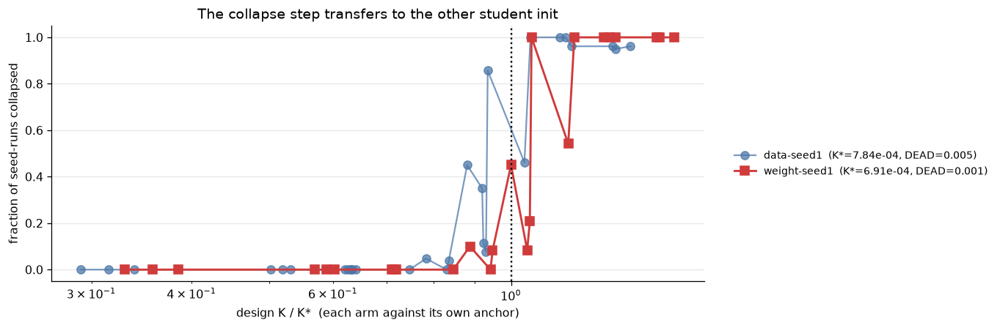

ws1 campaign K* (geometric mean of mixed cells): 7.021e-04 [mixed band 6.14e-04 - 8.15e-04, n_mixed=6]
ws1 anchor K* (law-* weight-seed1 arms):         6.913e-04
ratio campaign / anchor:                         1.02x
alive_max = 6.52e-04, dead_min = 7.33e-04 (clean separation)

ds1 for reference: campaign 8.035e-04 = 1.02x its anchor

majority-verdict misses when thresholding ws1 at its ANCHOR K*:
  all 25 landed cells         : 2/25 cells misclassified
  wave 1 (pre-registered)     : 1/16 cells misclassified
  wave 2 (rank extension)     : 1/9 cells misclassified


In [18]:
# (a) pooled collapse curve, both arms on their OWN anchors
rung_ws = (wsr.groupby("student_tag", observed=True)
           .agg(K_rel=("K_rel", "first"), K_rel_ds=("K_rel_ds", "first"),
                frac=("collapsed", "mean"), n=("collapsed", "size"),
                p_alive=("test", lambda s: s[s >= DEAD_WS].mean()))
           .reindex(WS_CELL_ORDER))
rung_ds = (runs.groupby("student_tag", observed=True)
           .agg(K_rel=("K_rel", "first"), frac=("collapsed", "mean"))
           .reindex(CELL_ORDER))

fig, ax = plt.subplots(figsize=(9.6, 4.0))
ax.plot(rung_ds.K_rel, rung_ds.frac, "o-", color="#4c78a8", lw=1.4, ms=7, alpha=.75,
        label=f"data-seed1  (K*={KSTAR_DESIGN:.2e}, DEAD={DEAD})")
ax.plot(rung_ws.K_rel, rung_ws.frac, "s-", color="#d03b3b", lw=1.8, ms=8,
        label=f"weight-seed1  (K*={KSTAR_WS1:.2e}, DEAD={DEAD_WS})")
ax.axvline(1.0, color="k", ls=":", lw=1.5)
ax.set(xscale="log", xlabel="design K / K*  (each arm against its own anchor)",
       ylabel="fraction of seed-runs collapsed",
       title="The collapse step transfers to the other student init")
fig.legend(loc="center left", bbox_to_anchor=(0.90, 0.5), frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 0.89, 1)); plt.show()

# (b) boundary + misses on ws1
ks_ws = cl.estimate_kstar(wsr, B_LAW, C_LAW)
print(f"ws1 campaign K* (geometric mean of mixed cells): {ks_ws['kstar']:.3e} "
      f"[mixed band {ks_ws['band'][0]:.2e} - {ks_ws['band'][1]:.2e}, n_mixed={ks_ws['n_mixed']}]")
print(f"ws1 anchor K* (law-* weight-seed1 arms):         {KSTAR_WS1:.3e}")
print(f"ratio campaign / anchor:                         {ks_ws['kstar'] / KSTAR_WS1:.2f}x")
print(f"alive_max = {ks_ws['alive_max']:.2e}, dead_min = {ks_ws['dead_min']:.2e} "
      + ("(clean separation)" if ks_ws["alive_max"] < ks_ws["dead_min"] else "(bands overlap)"))
print(f"\nds1 for reference: campaign {cl.estimate_kstar(runs, B_LAW, C_LAW)['kstar']:.3e} "
      f"= {cl.estimate_kstar(runs, B_LAW, C_LAW)['kstar'] / KSTAR_DESIGN:.2f}x its anchor")

print("\nmajority-verdict misses when thresholding ws1 at its ANCHOR K*:")
for name, sub in ([(f"all {len(WS_CELLS)} landed cells", wsr)]
                  + [(WAVE_NAME[w], wsr[wsr.wave.eq(w)]) for w in sorted(wsr.wave.unique())]):
    if sub.empty:
        print(f"  {name:28s}: no data")
        continue
    wrong, ncells = cl.law_misses(sub, B_LAW, C_LAW, KSTAR_WS1)
    print(f"  {name:28s}: {wrong}/{ncells} cells misclassified")

### 9.3 The `weight-seed1` campaign in one matrix

§4's view, rebuilt for the second arm: rows are the 25 cells sorted by design $K/K^\ast$
**against the ws1 anchor**, columns are the same 20 teachers in distillability order, red
boxes mark cells at/below `DEAD_WS`, and the dashed line is that arm's $K/K^\ast = 1$.
(No wave-3 rows here — that extension was never queued on this init.)

Three panels, because one colour scale cannot answer both questions:

- **(a) ws1 on its own scale** — readable internal structure. This is the direct analogue of §4.
- **(b) ws1 on §4's exact scale** (`vmax=0.2`) — the honest cross-arm comparison. The whole
  matrix going dim *is* the finding; it is not a rendering problem.
- **(c) ds1 − ws1 per cell** — where the init penalty actually lands. If it were a uniform
  offset the panel would be flat; structure here means some teachers or rungs lose far more
  than others.

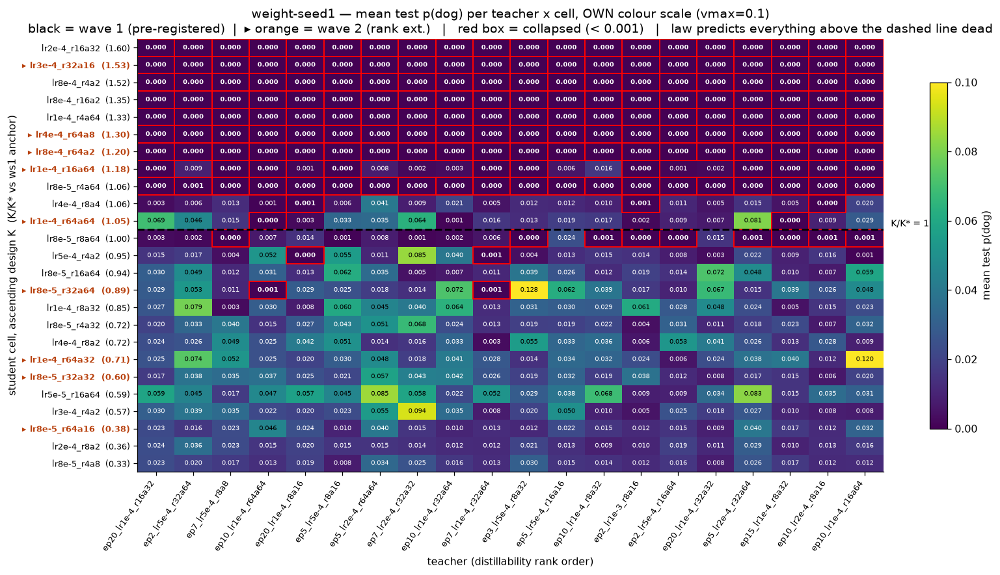

In [19]:
# Shared construction for all three panels.
WS_CELL_LABEL = cell_labels(WS_CELL_ORDER, KSTAR_WS1)
mat_ws = (wsr.pivot_table(index="student_tag", columns="teacher", values="test",
                          aggfunc="mean", observed=False)
          .reindex(index=WS_CELL_ORDER, columns=TEACHERS))
n_below_ws = sum(design_K(t) < KSTAR_WS1 for t in WS_CELL_ORDER)


def _ws_matrix(ax, grid, vmax, dead, title):
    """Draw one ws1 teacher x cell panel with §4's furniture (K/K*=1 rule, wave colours)."""
    im = arm_matrix(ax, grid.rename(index=WS_CELL_LABEL), WS_CELL_ORDER, n_below_ws,
                    vmax=vmax, dead=dead,
                    ylabel="student cell, ascending design K  (K/K* vs ws1 anchor)")
    ax.set_title(title)
    return im


# (a) ws1 on its own scale -- the readable view.
VMAX_WS = 0.10
fig, ax = plt.subplots(figsize=(14.5, 7.8))
im = _ws_matrix(ax, mat_ws, VMAX_WS, DEAD_WS,
                "weight-seed1 — mean test p(dog) per teacher x cell, OWN colour scale "
                f"(vmax={VMAX_WS})\n"
                "black = wave 1 (pre-registered)  |  ▸ orange = wave 2 (rank ext.)   |   "
                f"red box = collapsed (< {DEAD_WS})   |   law predicts everything above the dashed line dead")
fig.colorbar(im, ax=ax, shrink=0.8, label="mean test p(dog)")
fig.tight_layout(); plt.show()

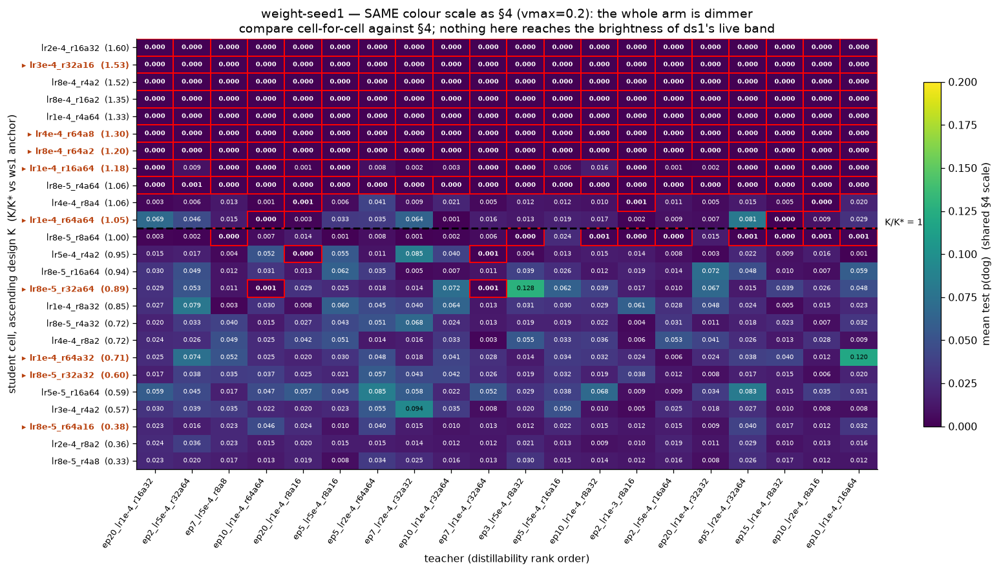

cell-mean p(dog):  ds1 max 0.385   ws1 max 0.128   (0.33x)


In [20]:
# (b) the same matrix on §4's scale -- what the arm looks like next to ds1.
fig, ax = plt.subplots(figsize=(14.5, 7.8))
im = _ws_matrix(ax, mat_ws, 0.2, DEAD_WS,
                "weight-seed1 — SAME colour scale as §4 (vmax=0.2): the whole arm is dimmer\n"
                "compare cell-for-cell against §4; nothing here reaches the brightness of ds1's live band")
fig.colorbar(im, ax=ax, shrink=0.8, label="mean test p(dog)  (shared §4 scale)")
fig.tight_layout(); plt.show()

print(f"cell-mean p(dog):  ds1 max {mat.max().max():.3f}   ws1 max {mat_ws.max().max():.3f}"
      f"   ({mat_ws.max().max() / mat.max().max():.2f}x)")

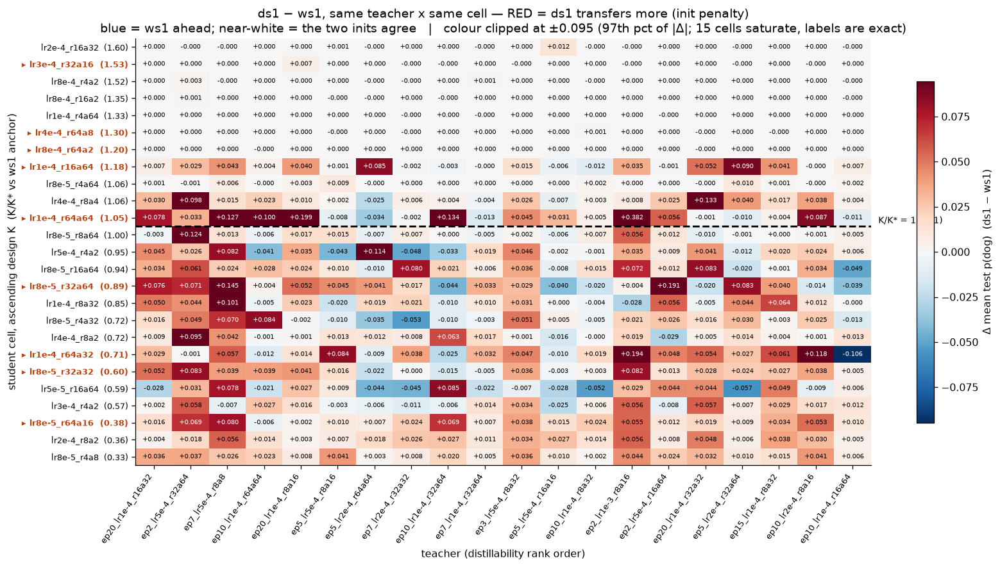

Δ over 500 teacher x cell pairs: median +0.0016, mean +0.0153, ds1 ahead in 75% of them
restricted to the 14 rows below the ws1 cliff: median +0.0145, ds1 ahead in 75%

largest per-teacher mean Δ (init penalty by teacher):


teacher,ep2_lr1e-3_r8a16,ep7_lr5e-4_r8a8,ep2_lr5e-4_r32a64,ep20_lr1e-4_r32a32,ep20_lr1e-4_r8a16
mean Δ (ds1-ws1),0.0448,0.0398,0.0372,0.0231,0.0208


In [21]:
# (c) ds1 - ws1 on the 25 shared cells: where does the init penalty concentrate?
mat_ds_shared = (runs.pivot_table(index="student_tag", columns="teacher", values="test",
                                  aggfunc="mean", observed=False)
                 .reindex(index=WS_CELL_ORDER, columns=TEACHERS))
delta = mat_ds_shared - mat_ws
# Robust symmetric limit: one +0.38 outlier would otherwise flatten the whole panel.
# Values beyond the limit still print their true number, they just saturate in colour.
lim = float(np.nanpercentile(np.abs(delta.values), 97))
n_clip = int((np.abs(delta.values) > lim).sum())

fig, ax = plt.subplots(figsize=(14.5, 7.8))
im = aplots.annotated_heatmap(ax, delta.rename(index=WS_CELL_LABEL), vmin=-lim, vmax=lim,
                              fmt="{:+.3f}", cell_fontsize=6, cmap="RdBu_r")
ax.axhline(n_below_ws - 0.5, color="k", ls="--", lw=1.8)
ax.text(len(TEACHERS) - 0.3, n_below_ws - 0.45, "K/K* = 1 (ws1)", fontsize=9, va="bottom")
for lbl, tag in zip(ax.get_yticklabels(), WS_CELL_ORDER):
    if WAVE[tag] > 1:
        lbl.set_color(WAVE_COLOR[WAVE[tag]]); lbl.set_fontweight("bold")
ax.set_xlabel("teacher (distillability rank order)")
ax.set_ylabel("student cell, ascending design K  (K/K* vs ws1 anchor)")
ax.set_title("ds1 − ws1, same teacher x same cell — RED = ds1 transfers more (init penalty)\n"
             f"blue = ws1 ahead; near-white = the two inits agree   |   colour clipped at ±{lim:.3f} "
             f"(97th pct of |Δ|; {n_clip} cells saturate, labels are exact)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Δ mean test p(dog)  (ds1 − ws1)")
fig.tight_layout(); plt.show()

d = delta.values[~np.isnan(delta.values)]
print(f"Δ over {len(d)} teacher x cell pairs: median {np.median(d):+.4f}, "
      f"mean {d.mean():+.4f}, ds1 ahead in {(d > 0).mean():.0%} of them")
alive_rows = [t for t in WS_CELL_ORDER if design_K(t) < KSTAR_WS1]
da = delta.loc[alive_rows].values[~np.isnan(delta.loc[alive_rows].values)]
print(f"restricted to the {len(alive_rows)} rows below the ws1 cliff: median {np.median(da):+.4f}, "
      f"ds1 ahead in {(da > 0).mean():.0%}")
print("\nlargest per-teacher mean Δ (init penalty by teacher):")
display(delta.mean().sort_values(ascending=False).head(5).round(4).to_frame("mean Δ (ds1-ws1)").T)

### 9.4 `data-seed1` vs `weight-seed1`, cell by cell

The two arms share all 25 cells and all 20 teachers, so they pair exactly. Two separable
questions, and they have different answers:

- **Does ws1 die earlier?** Compared at a *common* threshold and on raw $K$ (not $K/K^\ast$),
  so the anchors do not absorb the effect.
- **Do the survivors transfer as strongly?** Among cells alive in *both* arms, is p(dog) the
  same? This is a magnitude question the collapse law is silent about.

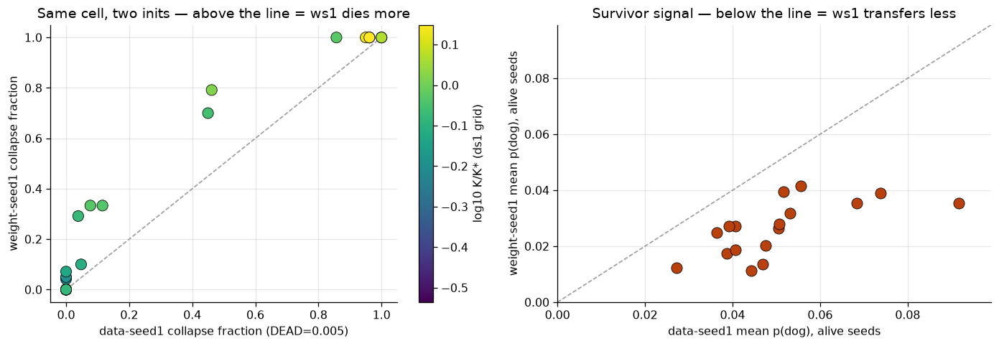

cells where ws1 collapses MORE than ds1 at DEAD=0.005: 14/25   (less: 0, tied: 11)
pooled collapse fraction  ds1 31.2%  vs  ws1 43.1%  (common threshold)
median ws1/ds1 ratio of survivor p(dog): 0.52  (ws1 weaker; n=17 cells alive in both)
best cell per arm:  ds1 0.092   ws1 0.042


,K_rel_ds1,ds1_frac,ws1_frac,ds1_p_alive,ws1_p_alive
lr8e-5_r4a8,0.291,0.000,0.000,0.039,0.018
lr2e-4_r8a2,0.315,0.000,0.000,0.041,0.019
lr8e-5_r64a16,0.339,0.000,0.000,0.048,0.020
lr3e-4_r4a2,0.502,0.000,0.000,0.041,0.027
lr5e-5_r16a64,0.519,0.000,0.000,0.052,0.039
lr8e-5_r32a32,0.531,0.000,0.000,0.051,0.026
lr1e-4_r64a32,0.626,0.000,0.000,0.068,0.035
lr4e-4_r8a2,0.631,0.000,0.042,0.053,0.032
lr8e-5_r4a32,0.634,0.000,0.050,0.039,0.027
lr1e-4_r8a32,0.747,0.000,0.071,0.056,0.042


In [22]:
# Common threshold for the paired contrast, so neither arm gets a bespoke advantage.
DEAD_COMMON = DEAD
ds_c = cl.label_collapse(runs, dead_seed=DEAD_COMMON)
ws_c = cl.label_collapse(wsr, dead_seed=DEAD_COMMON)
shared = [c for c in CELL_ORDER if c in set(WS_CELLS)]

def _arm_cell_stats(d, prefix):
    """Per-cell collapse fraction and survivor-only mean p(dog), indexed by student_tag."""
    g = d.groupby("student_tag", observed=True)
    return pd.DataFrame({f"{prefix}_frac": g.collapsed.mean(),
                         f"{prefix}_p_alive": d[d.collapsed.eq(0)].groupby(
                             "student_tag", observed=True).test.mean()})


pair = (pd.DataFrame({"K_rel_ds1": ds_c.groupby("student_tag", observed=True).K_rel.first()})
        .join(_arm_cell_stats(ds_c, "ds1")).join(_arm_cell_stats(ws_c, "ws1"))
        .reindex(shared)[["K_rel_ds1", "ds1_frac", "ws1_frac", "ds1_p_alive", "ws1_p_alive"]]
        .set_axis([c.removeprefix("ep20_") for c in shared]))

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3))
ax = axes[0]
ax.plot([0, 1], [0, 1], ls="--", color="0.6", lw=1)
sc = ax.scatter(pair.ds1_frac, pair.ws1_frac, s=90, c=np.log10(pair.K_rel_ds1),
                cmap="viridis", edgecolor="k", linewidth=.5, zorder=3)
ax.set(xlabel=f"data-seed1 collapse fraction (DEAD={DEAD_COMMON})",
       ylabel="weight-seed1 collapse fraction",
       title="Same cell, two inits — above the line = ws1 dies more")
fig.colorbar(sc, ax=ax, label="log10 K/K* (ds1 grid)")

ax = axes[1]
m = pair.dropna(subset=["ds1_p_alive", "ws1_p_alive"])
hi = max(m[["ds1_p_alive", "ws1_p_alive"]].max()) * 1.08
ax.plot([0, hi], [0, hi], ls="--", color="0.6", lw=1)
ax.scatter(m.ds1_p_alive, m.ws1_p_alive, s=90, color="#b8410e", edgecolor="k",
           linewidth=.5, zorder=3)
ax.set(xlim=(0, hi), ylim=(0, hi), xlabel="data-seed1 mean p(dog), alive seeds",
       ylabel="weight-seed1 mean p(dog), alive seeds",
       title="Survivor signal — below the line = ws1 transfers less")
fig.tight_layout(); plt.show()

n_worse = int((pair.ws1_frac > pair.ds1_frac).sum())
n_better = int((pair.ws1_frac < pair.ds1_frac).sum())
ratio = (m.ws1_p_alive / m.ds1_p_alive).median()
print(f"cells where ws1 collapses MORE than ds1 at DEAD={DEAD_COMMON}: {n_worse}/{len(pair)}"
      f"   (less: {n_better}, tied: {len(pair) - n_worse - n_better})")
print(f"pooled collapse fraction  ds1 {ds_c.collapsed.mean():.1%}  vs  ws1 {ws_c.collapsed.mean():.1%}"
      f"  (common threshold)")
print(f"median ws1/ds1 ratio of survivor p(dog): {ratio:.2f}"
      f"  ({'ws1 weaker' if ratio < 1 else 'ws1 stronger'}; n={len(m)} cells alive in both)")
print(f"best cell per arm:  ds1 {pair.ds1_p_alive.max():.3f}   ws1 {pair.ws1_p_alive.max():.3f}")
display(pair.round(3))

### 9.5 Fixed-$K$ twins on `weight-seed1`

§7's identifying test, repeated: each high-rank (r32/r64) wave-2 cell against its matched-$K$
wave-1 rung-mates. If $K$ is a sufficient statistic the twins must live and die together on
this init too.

In [23]:
ws_cell = (wsr.groupby("student_tag", observed=True)
           .agg(frac=("collapsed", "mean"), p_alive=("test", lambda s: s[s >= DEAD_WS].mean()),
                rank=("rank", "first"), alpha=("alpha", "first"), K=("K", "first")))
rows = []
for hi, los in sorted(TWINS.items(), key=lambda kv: design_K(kv[0])):
    los_here = [l for l in los if l in ws_cell.index]
    if hi not in ws_cell.index or not los_here:
        continue
    lo_frac = float(np.mean([ws_cell.loc[l, "frac"] for l in los_here]))
    lo_alive = np.nanmean([ws_cell.loc[l, "p_alive"] for l in los_here])
    kr = design_K(hi) / KSTAR_WS1
    rows.append(dict(
        K_rel_ws1=round(kr, 2), hi_cell=hi.removeprefix("ep20_"),
        hi_frac=round(float(ws_cell.loc[hi, "frac"]), 2), lo_frac=round(lo_frac, 2),
        agree="yes" if abs(ws_cell.loc[hi, "frac"] - lo_frac) < 0.5 else "NO",
        hi_p_alive=round(float(ws_cell.loc[hi, "p_alive"]), 4),
        lo_p_alive=round(float(lo_alive), 4),
        # a twin pair straddling the cliff cannot adjudicate sufficiency
        straddles="yes" if min(ws_cell.loc[hi, "frac"], lo_frac) < 0.5 < max(
            ws_cell.loc[hi, "frac"], lo_frac) else "",
        n_lo=len(los_here)))
twin_ws = pd.DataFrame(rows)
display(twin_ws)
if len(twin_ws):
    ok = int((twin_ws.agree == "yes").sum())
    print(f"binary verdict agrees on {ok}/{len(twin_ws)} twin rungs "
          f"({int((twin_ws.straddles == 'yes').sum())} straddle the cliff and cannot adjudicate)")
    mg = twin_ws.dropna(subset=["hi_p_alive", "lo_p_alive"])
    mg = mg[mg.lo_p_alive > 0]
    if len(mg):
        print(f"median high/low-rank survivor p(dog) ratio at matched K: "
              f"{(mg.hi_p_alive / mg.lo_p_alive).median():.2f}  (n={len(mg)} rungs)")

,K_rel_ws1,hi_cell,hi_frac,lo_frac,agree,hi_p_alive,lo_p_alive,straddles,n_lo
0,0.38,lr8e-5_r64a16,0.00,0.00,yes,0.0203,0.0186,,1
1,0.60,lr8e-5_r32a32,0.00,0.00,yes,0.0264,0.0333,,2
2,0.71,lr1e-4_r64a32,0.00,0.00,yes,0.0353,0.0283,,2
3,0.89,lr8e-5_r32a64,0.10,0.03,yes,0.0389,0.0289,,3
4,1.05,lr1e-4_r64a64,0.08,0.35,yes,0.0263,0.0169,,5
5,1.20,lr8e-4_r64a2,1.00,0.74,yes,NaN,0.0119,,3
6,1.30,lr4e-4_r64a8,1.00,1.00,yes,NaN,NaN,,2
7,1.53,lr3e-4_r32a16,1.00,1.00,yes,NaN,NaN,,3


binary verdict agrees on 8/8 twin rungs (0 straddle the cliff and cannot adjudicate)
median high/low-rank survivor p(dog) ratio at matched K: 1.25  (n=5 rungs)


### 9.6 What the second arm adds

**The law transfers; the threshold does not.** On its own anchor the ws1 campaign recovers
$K^\ast = 7.02\times10^{-4}$ against a pre-registered $6.91\times10^{-4}$ — a ratio of
**1.02×**, with clean alive/dead separation and **2/25** majority-verdict misses (1/16 on the
pre-registered wave 1). That is the same 1.02× fidelity the ds1 arm achieves on *its* anchor,
so the composite $K = \mathrm{lr}\cdot\alpha^{0.561} r^{-0.085}$ and the per-init $K^\ast$
together carry across the init change. What emphatically does *not* carry across is the
**collapse threshold**: scored at ds1's `DEAD`, ws1's anchor looks missed by 0.71× — a
thresholding artefact, not a law failure, because the ws1 live mode is compressed toward zero
and its trough sits at $10^{-3}$ rather than $5\times10^{-3}$ (§9.1). This is the same
"threshold is arm-specific" lesson the `law-*` campaign hit, and it is the single easiest way
to misread this arm.

**`weight-seed1` is uniformly the harder init — in both senses.** At a common threshold, 14 of
25 cells collapse more on ws1 and **none collapse less** (11 tied), pooling to 43.1% vs 31.2%.
Among the 17 cells alive in *both* arms, the median ws1/ds1 survivor p(dog) ratio is **0.52** —
survivors transfer about half as strongly — and the best cell in the whole arm reaches 0.042
against ds1's 0.092. So the init penalty is not merely a shifted cliff that a lower learning
rate could buy back: even well inside the alive band, cross-init transfer into weight-seed1
delivers roughly half the signal. Part of the collapse gap is the 1.13× placement shift, but
the magnitude gap is independent of it.

**$K$ stays sufficient at high rank.** All **8/8** fixed-$K$ twin rungs agree on the binary
verdict, none straddling the cliff, so the r32/r64 cells live and die where their low-rank
rung-mates do on this init too. The survivor-magnitude ratio is 1.25 in favour of high rank —
same direction as §7's ds1 result, i.e. rank buys a little signal that the scalar $K$ does not
capture, and it is a statement about the law's *form*, not its boundary.

## 10. Reading guide

- **Law verified** requires, on complete data: (i) the §5a step crosses 0.5 near
  $K/K^\ast = 1$; (ii) §5b's campaign $K^\ast$ within the mixed band of the anchor and few
  majority misses — *on wave 1 in particular*, which is the pre-registered half; (iii) §5c
  monotone for (nearly) all teachers with boundaries clustered near 1. Deviations are
  findings, not failures — a shifted boundary would say the *cross-init* cliff sits elsewhere
  than the same-lineage one it was fitted on.
- **$K$ sufficient** splits in two, and §7 answers them differently. For the *binary verdict*
  the two rank clouds should coincide (§7a) and the paired fixed-$K$ twins agree rung by rung
  (§7b(i)) — discount any rung flagged `straddles`, where the ±12% match window spans the
  whole cliff. For the *magnitude*, §7b(ii) asks whether survivors reach the same p(dog) at
  matched $K$; a ratio persistently above 1 means rank carries signal the scalar $K$ does not,
  which is a statement about the law's form, not its boundary. Cross-check any residual rank
  effect against the §5d refit on the merged (rank 4–64) design, which is the only place $c$
  is properly identified.
- **Waves are an annotation, not a filter.** All 25 cells enter every descriptive section;
  the split is reported only where pre-registration status changes what a number means
  (§5b, §5d, and the `wave` column in §7c/§8). Wave-2 cells were placed after early
  law-grid reads, so they earn no pre-registration credit — but they are the only cells that
  identify the rank term.
- Seed 1 only: per-(teacher, cell) collapse is 0/1, so all fractions here average across
  teachers, not seeds; σ-style claims belong to the 3-seed control arm
  (`ctrl-base-krungs`), not this notebook.
- Non-design ep20 cells (the two law-* teachers carry full grids) are deliberately excluded;
  see `collapse_law_generality.ipynb` for those.
- **The two arms are scored at different thresholds, on purpose.** §2 sets `DEAD` from the
  ds1 trough and §9.1 sets `DEAD_WS` from the ws1 trough; each is the emptiest interior bin
  of *that* arm's own distribution. Never quote a cross-init collapse comparison at a single
  inherited threshold — §9.4's paired contrast deliberately re-scores both arms at a common
  `DEAD` for exactly that reason, and §9.1's sensitivity table shows how much the choice
  moves each arm (ds1 barely, ws1 a lot).
- **`K/K*` is per-init.** §9 normalises ws1 by its own anchor; the `K_rel_ds` column keeps
  the ds1-grid value the cells were actually *placed* on. The 1.13× gap between them is why
  ws1 samples further past the cliff and so shows more dead cells before any init effect is
  invoked — separate the placement shift from the init penalty before attributing either.
- **§9.3's three panels answer different questions.** Panel (a) is the readable ws1 matrix,
  (b) is the only one colour-comparable to §4, and (c) localises the init penalty. Quoting
  brightness across (a) and §4 is a scale error — use (b).
- **Collapse and magnitude are different claims.** The law governs *whether* a cell dies;
  §9.4's survivor panel governs *how much* signal a live cell carries. ws1 is worse on both,
  but only the first is what §9.2 verifies.